# Deep Learning-Based Classification of Air Pollution Levels from Sky Images

### MCA Capstone Project-I

**Team Members:**
- Shaswat Singh — S25MCAG0105
- Deepak Kumar — S25MCAG0088

**Mentor:** Dr. Anurag Shrivastava

---

## Project Objective

This project aims to classify air pollution levels from sky and urban images using deep learning and computer vision techniques.

The project uses a six-class air pollution image dataset and compares a custom CNN baseline with a transfer learning model to identify the model that provides better generalization performance.

### Pollution Classes

1. Good
2. Moderate
3. Unhealthy for Sensitive Groups
4. Unhealthy
5. Very Unhealthy
6. Severe

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

### Explainability

Grad-CAM will be used to visualize the image regions that contribute to the model's prediction.

In [8]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("All required libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All required libraries imported successfully!
TensorFlow version: 2.21.0


In [9]:
# ============================================================
# CELL 3 — SET RANDOM SEEDS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [10]:
# ============================================================
# CELL 4 — DATASET CONFIGURATION
# ============================================================

ZIP_PATH = "capstone project archive.zip"
ROOT_DIR = "air_pollution_dataset"

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

print("Dataset configuration completed.")
print("ZIP file:", ZIP_PATH)
print("Dataset folder:", ROOT_DIR)

Dataset configuration completed.
ZIP file: capstone project archive.zip
Dataset folder: air_pollution_dataset


In [11]:
# ============================================================
# CELL 5 — EXTRACT DATASET
# ============================================================

import zipfile

if not os.path.exists(ROOT_DIR):

    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(
            f"ZIP file not found: {ZIP_PATH}"
        )

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(ROOT_DIR)

    print("✅ Dataset extracted successfully!")

else:
    print("✅ Dataset folder already exists.")
    print("Skipping extraction.")

print("Dataset location:", os.path.abspath(ROOT_DIR))

✅ Dataset folder already exists.
Skipping extraction.
Dataset location: C:\Users\shasw\air_pollution_dataset


In [13]:
# ============================================================
# CELL 7 — DATASET VERIFICATION
# ============================================================

import os

ROOT_DIR = "air_pollution_dataset"

# Automatically find IND_and_NEP folder
dataset_path = None

for root, dirs, files in os.walk(ROOT_DIR):
    if "IND_and_NEP" in dirs:
        possible_path = os.path.join(root, "IND_and_NEP")

        # Check whether this is the correct dataset folder
        folders = [
            folder
            for folder in os.listdir(possible_path)
            if os.path.isdir(os.path.join(possible_path, folder))
        ]

        if len(folders) >= 6:
            dataset_path = possible_path
            break

# Stop if dataset was not found
if dataset_path is None:
    raise FileNotFoundError(
        "IND_and_NEP dataset folder was not found."
    )

# Get class folders
class_names = sorted([
    folder
    for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

# Count images in every class
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}

for class_name in class_names:
    class_folder = os.path.join(dataset_path, class_name)

    count = sum(
        1
        for file in os.listdir(class_folder)
        if file.lower().endswith(image_extensions)
    )

    class_counts[class_name] = count

total_images = sum(class_counts.values())

# Display results
print("=" * 60)
print("AIR POLLUTION DATASET VERIFICATION")
print("=" * 60)

print("\nDataset path:")
print(os.path.abspath(dataset_path))

print("\nClass folders:")
for class_name in class_names:
    print(f" - {class_name}")

print("\nNumber of classes:", len(class_names))

print("\nImage count by class:")
for class_name, count in class_counts.items():
    print(f"{class_name:45s}: {count}")

print("-" * 60)
print("TOTAL IMAGES:", total_images)
print("TOTAL CLASSES:", len(class_names))
print("=" * 60)

AIR POLLUTION DATASET VERIFICATION

Dataset path:
C:\Users\shasw\air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Combined_Dataset\IND_and_NEP

Class folders:
 - a_Good
 - b_Moderate
 - c_Unhealthy_for_Sensitive_Groups
 - d_Unhealthy
 - e_Very_Unhealthy
 - f_Severe

Number of classes: 6

Image count by class:
a_Good                                       : 1541
b_Moderate                                   : 1573
c_Unhealthy_for_Sensitive_Groups             : 2863
d_Unhealthy                                  : 2622
e_Very_Unhealthy                             : 2194
f_Severe                                     : 1447
------------------------------------------------------------
TOTAL IMAGES: 12240
TOTAL CLASSES: 6


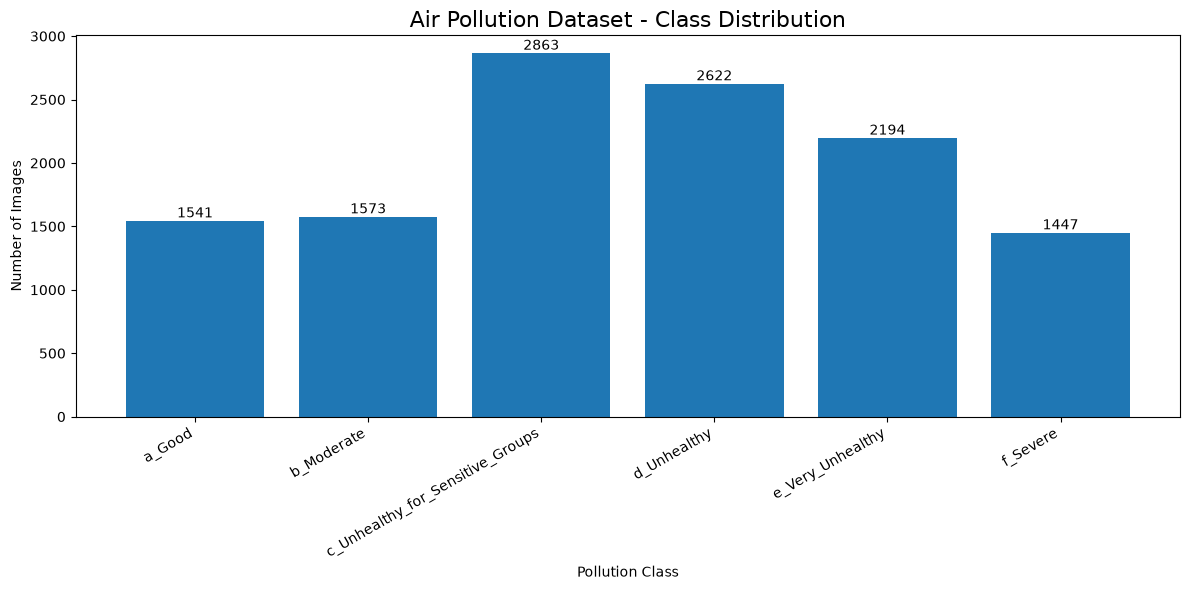

In [14]:
# ============================================================
# CELL 8 — CLASS DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

bars = plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title(
    "Air Pollution Dataset - Class Distribution",
    fontsize=16
)

plt.xlabel("Pollution Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=30,
    ha="right"
)

# Show image count above each bar
for bar, count in zip(bars, class_counts.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        str(count),
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# CELL 9 — TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Create image dataframe
image_paths = []
labels = []

for class_name in class_names:
    class_folder = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_folder):
        if filename.lower().endswith(image_extensions):
            image_paths.append(
                os.path.join(class_folder, filename)
            )
            labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("=" * 60)
print("DATAFRAME CREATED")
print("=" * 60)
print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

# ------------------------------------------------------------
# 80% Training + 10% Validation + 10% Testing
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("\n" + "=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))
print("Total             :", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df["label"].value_counts().sort_index())

DATAFRAME CREATED
Total images: 12240
Total classes: 6

DATASET SPLIT
Training images   : 9792
Validation images : 1224
Testing images    : 1224
Total             : 12240

Training distribution:
label
a_Good                              1233
b_Moderate                          1258
c_Unhealthy_for_Sensitive_Groups    2290
d_Unhealthy                         2098
e_Very_Unhealthy                    1755
f_Severe                            1158
Name: count, dtype: int64

Validation distribution:
label
a_Good                              154
b_Moderate                          157
c_Unhealthy_for_Sensitive_Groups    287
d_Unhealthy                         262
e_Very_Unhealthy                    220
f_Severe                            144
Name: count, dtype: int64

Testing distribution:
label
a_Good                              154
b_Moderate                          158
c_Unhealthy_for_Sensitive_Groups    286
d_Unhealthy                         262
e_Very_Unhealthy                    219


In [16]:
# ============================================================
# CELL 10 — IMAGE PREPROCESSING & DATA GENERATORS
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image size for deep learning models
IMG_SIZE = (224, 224)

# Batch size
BATCH_SIZE = 32

# Number of classes
NUM_CLASSES = len(class_names)

# ------------------------------------------------------------
# Training preprocessing + augmentation
# ------------------------------------------------------------

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],
    fill_mode="nearest"
)

# ------------------------------------------------------------
# Validation/Test preprocessing
# IMPORTANT: NO AUGMENTATION HERE
# ------------------------------------------------------------

valid_test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

# ------------------------------------------------------------
# Training generator
# ------------------------------------------------------------

train_data = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=True,
    seed=SEED
)

# ------------------------------------------------------------
# Validation generator
# ------------------------------------------------------------

validation_data = valid_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=False
)

# ------------------------------------------------------------
# Test generator
# ------------------------------------------------------------

test_data = valid_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=False
)

print("=" * 60)
print("DATA GENERATORS CREATED SUCCESSFULLY")
print("=" * 60)

print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Classes    :", NUM_CLASSES)

print("\nTraining samples   :", train_data.samples)
print("Validation samples :", validation_data.samples)
print("Testing samples    :", test_data.samples)

print("\nClass indices:")
print(train_data.class_indices)

Found 9792 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.
DATA GENERATORS CREATED SUCCESSFULLY
Image size : (224, 224)
Batch size : 32
Classes    : 6

Training samples   : 9792
Validation samples : 1224
Testing samples    : 1224

Class indices:
{'a_Good': 0, 'b_Moderate': 1, 'c_Unhealthy_for_Sensitive_Groups': 2, 'd_Unhealthy': 3, 'e_Very_Unhealthy': 4, 'f_Severe': 5}


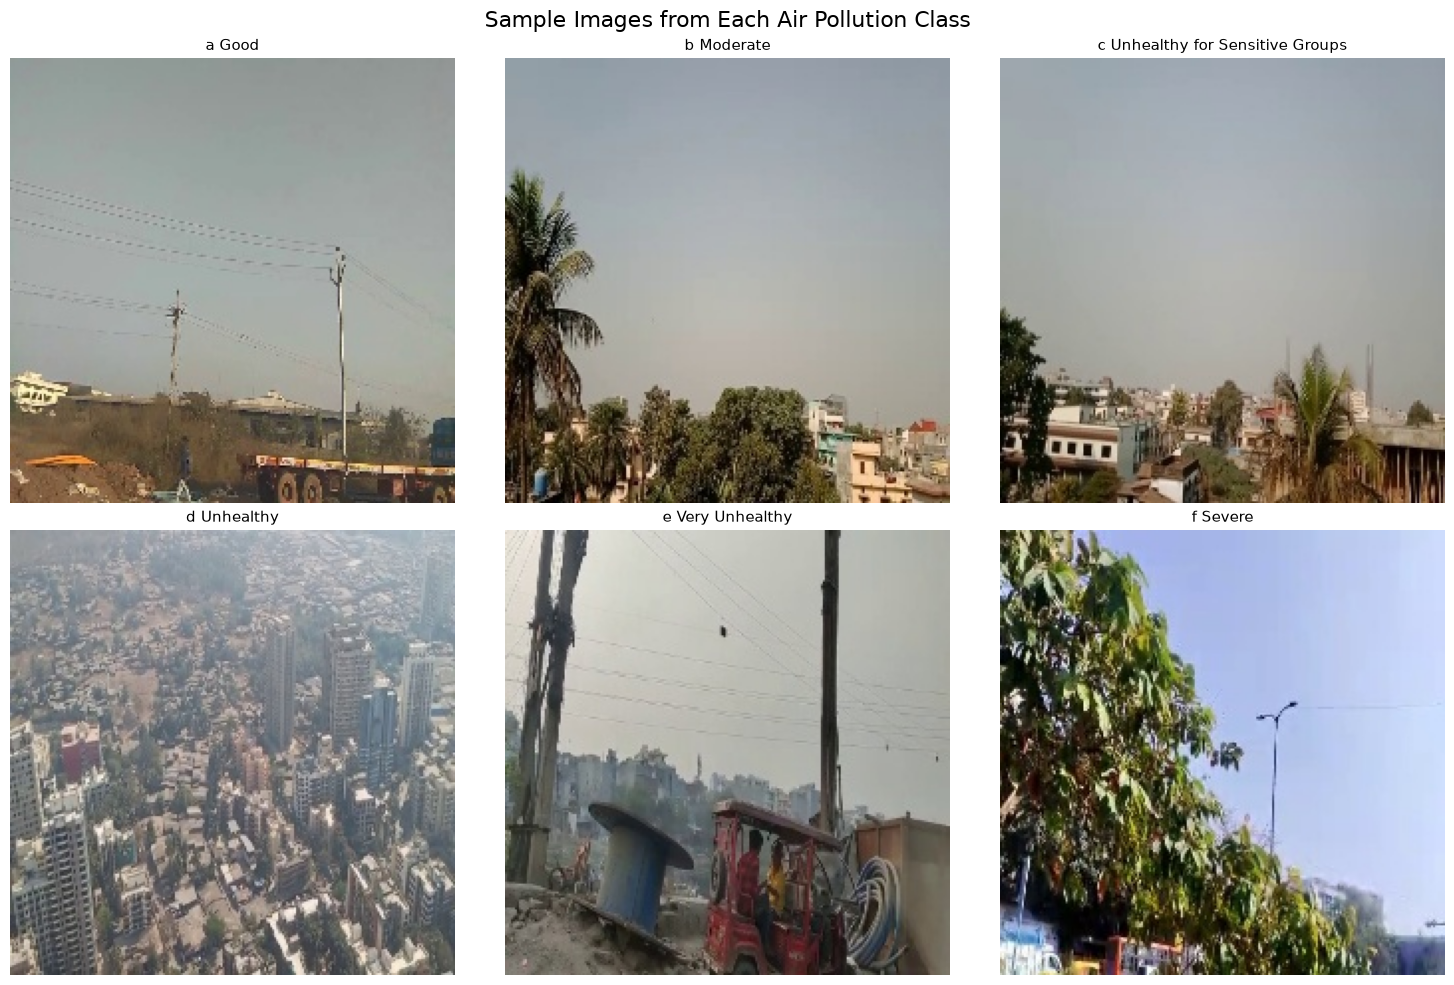

In [17]:
# ============================================================
# CELL 11 — SAMPLE IMAGES VISUALIZATION
# ============================================================

import random
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(class_names):

    # Images belonging to this class
    class_images = train_df[
        train_df["label"] == class_name
    ]["filepath"].values

    # Select one random image
    image_path = random.choice(class_images)

    # Load image
    image = load_img(image_path, target_size=IMG_SIZE)

    # Plot
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name.replace("_", " "), fontsize=11)
    plt.axis("off")

plt.suptitle(
    "Sample Images from Each Air Pollution Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# CELL 12 — CLASS WEIGHTS
# ============================================================

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Convert class labels to numerical indices
train_labels_numeric = train_df["label"].map(
    train_data.class_indices
).values

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_labels_numeric
)

# Create dictionary for Keras
class_weights = {
    index: float(weight)
    for index, weight in enumerate(weights)
}

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

for class_name, index in train_data.class_indices.items():
    print(
        f"{class_name:45s}: "
        f"{class_weights[index]:.4f}"
    )

CLASS WEIGHTS
a_Good                                       : 1.3236
b_Moderate                                   : 1.2973
c_Unhealthy_for_Sensitive_Groups             : 0.7127
d_Unhealthy                                  : 0.7779
e_Very_Unhealthy                             : 0.9299
f_Severe                                     : 1.4093


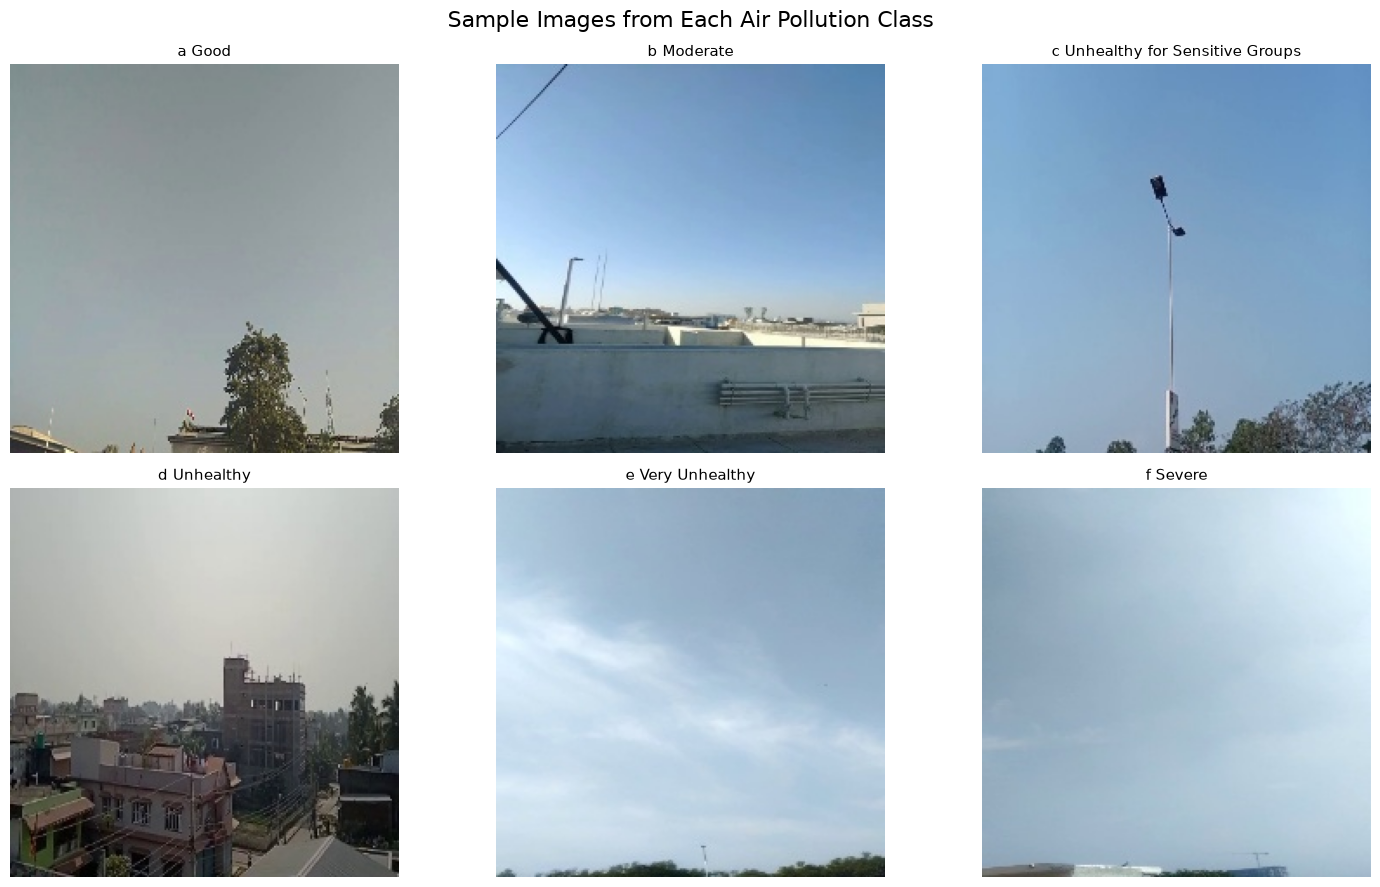

In [19]:
# ============================================================
# CELL 13 — SAMPLE IMAGES FROM EACH CLASS
# ============================================================

import random
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, class_name in zip(axes.flat, class_names):

    # Get images for this class
    class_images = train_df[
        train_df["label"] == class_name
    ]["filepath"].values

    # Select one random image
    image_path = random.choice(class_images)

    # Load image
    image = load_img(
        image_path,
        target_size=IMG_SIZE
    )

    # Display image
    ax.imshow(image)
    ax.set_title(
        class_name.replace("_", " "),
        fontsize=11
    )
    ax.axis("off")

plt.suptitle(
    "Sample Images from Each Air Pollution Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# CELL 14 — CUSTOM CNN BASELINE MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models

# Reproducibility
tf.random.set_seed(SEED)

# Build CNN model
cnn_model = models.Sequential([
    
    # Input
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.40),

    # Output
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Compile model
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 256)                 │           1,0

 Total params: 458,694 (1.75 MB)

 Trainable params: 457,222 (1.74 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [21]:
# ============================================================
# CELL 15 — TRAIN CUSTOM CNN
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_custom_cnn.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

# ------------------------------------------------------------
# Train CNN
# ------------------------------------------------------------

print("=" * 60)
print("STARTING CUSTOM CNN TRAINING")
print("=" * 60)

cnn_history = cnn_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],
    verbose=1
)

print("\n" + "=" * 60)
print("CUSTOM CNN TRAINING COMPLETED")
print("=" * 60)

STARTING CUSTOM CNN TRAINING
Epoch 1/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4286 - loss: 1.5331
Epoch 1: val_accuracy improved from None to 0.21405, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 566s 2s/step - accuracy: 0.4286 - loss: 1.5331 - val_accuracy: 0.2141 - val_loss: 3.8961 - learning_rate: 0.0010
Epoch 2/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5421 - loss: 1.1198
Epoch 2: val_accuracy improved from 0.21405 to 0.44526, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 536s 2s/step - accuracy: 0.5421 - loss: 1.1198 - val_accuracy: 0.4453 - val_loss: 1.6875 - learning_rate: 0.0010
Epoch 3/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6179 - loss: 0.9149
Epoch 3: val_accuracy improved from 0.44526 to 0.53922, saving model to best_custom_cnn.keras

Epoch 3: finished saving model to best

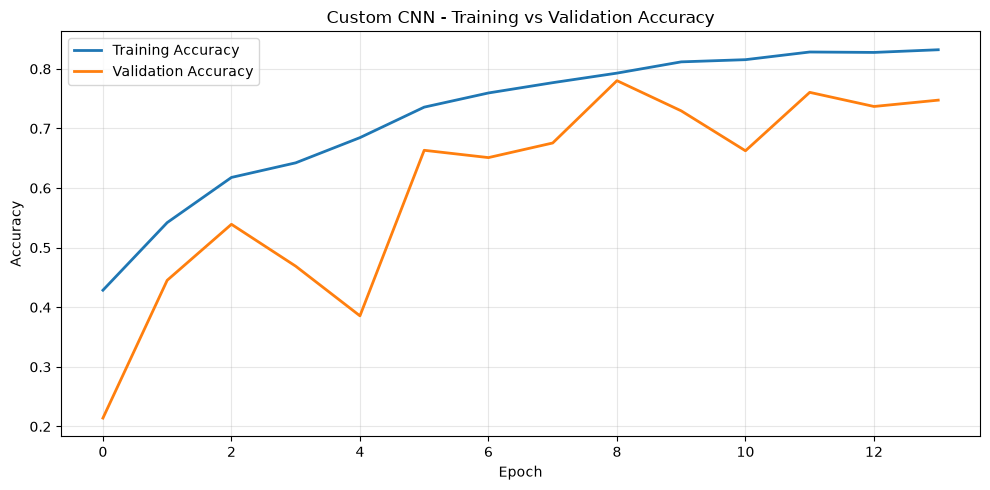

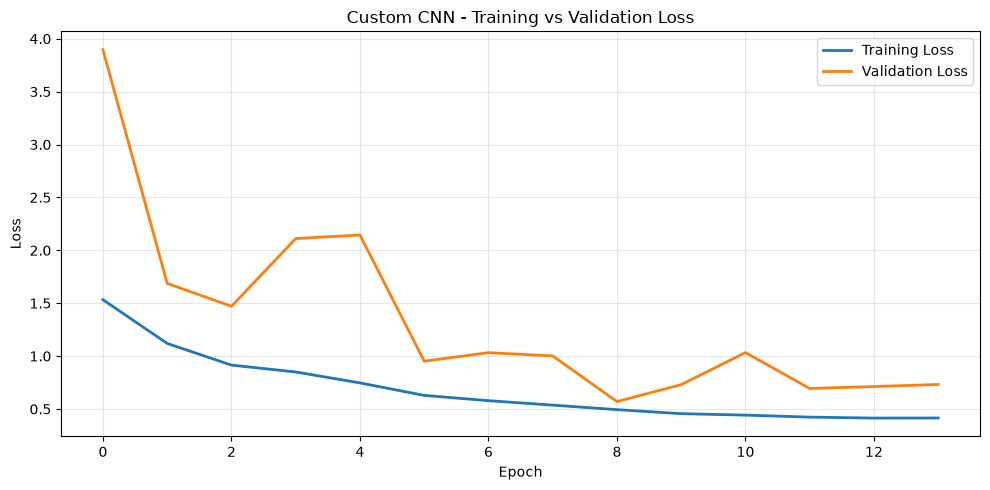

In [22]:
# ============================================================
# CELL 16 — CUSTOM CNN TRAINING PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt

history = cnn_history.history

# Accuracy
plt.figure(figsize=(10, 5))

plt.plot(history["accuracy"], label="Training Accuracy", linewidth=2)
plt.plot(history["val_accuracy"], label="Validation Accuracy", linewidth=2)

plt.title("Custom CNN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Loss
plt.figure(figsize=(10, 5))

plt.plot(history["loss"], label="Training Loss", linewidth=2)
plt.plot(history["val_loss"], label="Validation Loss", linewidth=2)

plt.title("Custom CNN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 647ms/step
CUSTOM CNN — TEST SET EVALUATION

Test Accuracy: 78.10%

Classification Report:
                                  precision    recall  f1-score   support

                          a_Good     0.7831    0.8442    0.8125       154
                      b_Moderate     0.6985    0.8797    0.7787       158
c_Unhealthy_for_Sensitive_Groups     0.7248    0.6538    0.6875       286
                     d_Unhealthy     0.7321    0.7405    0.7362       262
                e_Very_Unhealthy     0.9351    0.7900    0.8564       219
                        f_Severe     0.8808    0.9172    0.8986       145

                        accuracy                         0.7810      1224
                       macro avg     0.7924    0.8042    0.7950      1224
                    weighted avg     0.7864    0.7810    0.7807      1224



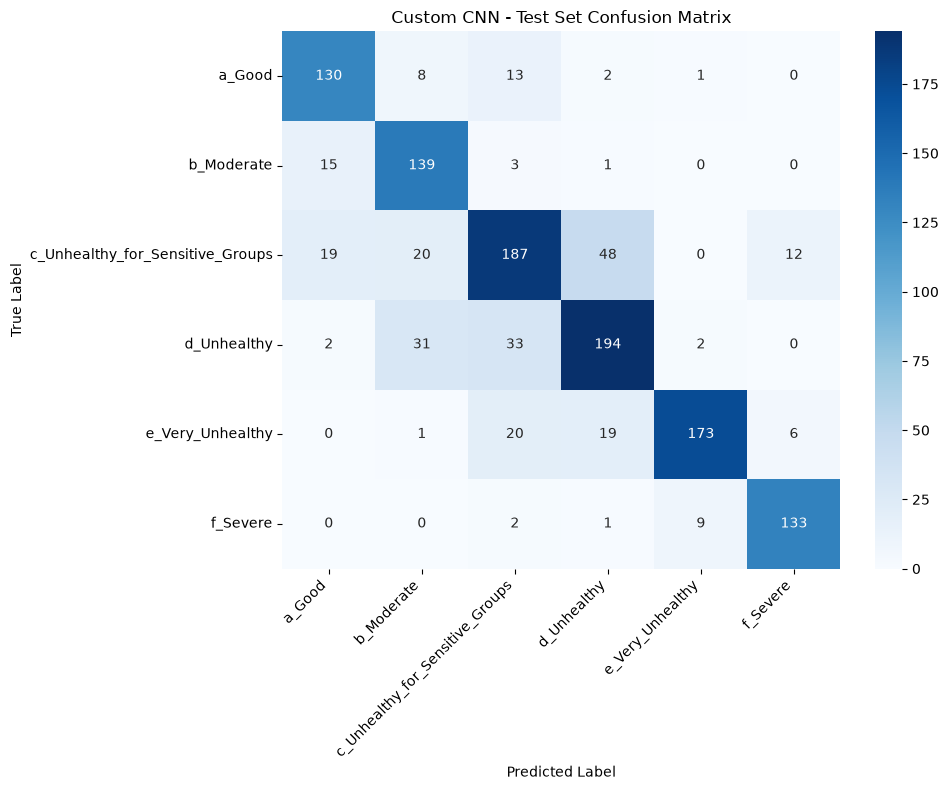

In [23]:
# ============================================================
# CELL 17 — CUSTOM CNN TEST SET EVALUATION
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure test generator starts from the beginning
test_data.reset()

# Predict on completely unseen test data
test_predictions = cnn_model.predict(test_data, verbose=1)

# Convert probabilities to class indices
y_pred = np.argmax(test_predictions, axis=1)

# True labels
y_true = test_data.classes

# Test accuracy
cnn_test_accuracy = accuracy_score(y_true, y_pred)

print("=" * 60)
print("CUSTOM CNN — TEST SET EVALUATION")
print("=" * 60)

print(f"\nTest Accuracy: {cnn_test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# CELL 18 — EFFICIENTNETB0 TRANSFER LEARNING MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build classification model
efficientnet_model = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.40),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

# Compile
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("=" * 60)
print("EFFICIENTNETB0 MODEL")
print("=" * 60)

efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
EFFICIENTNETB0 MODEL


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │           1,542 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,384,169 (16.72 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [25]:
# ============================================================
# CELL 19 — EFFICIENTNETB0 INITIAL TRAINING
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Callbacks
efficientnet_callbacks = [

    EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        "efficientnetb0_best.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

print("=" * 60)
print("STARTING EFFICIENTNETB0 TRAINING")
print("=" * 60)

efficientnet_history = efficientnet_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=efficientnet_callbacks,
    verbose=1
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 INITIAL TRAINING COMPLETED")
print("=" * 60)

STARTING EFFICIENTNETB0 TRAINING
Epoch 1/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 851ms/step - accuracy: 0.1690 - loss: 2.1385
Epoch 1: val_accuracy improved from None to 0.23203, saving model to efficientnetb0_best.keras

Epoch 1: finished saving model to efficientnetb0_best.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 301s 926ms/step - accuracy: 0.1690 - loss: 2.1385 - val_accuracy: 0.2320 - val_loss: 1.7907 - learning_rate: 0.0010
Epoch 2/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.1749 - loss: 1.8898
Epoch 2: val_accuracy did not improve from 0.23203
306/306 ━━━━━━━━━━━━━━━━━━━━ 231s 753ms/step - accuracy: 0.1749 - loss: 1.8898 - val_accuracy: 0.1258 - val_loss: 1.7922 - learning_rate: 0.0010
Epoch 3/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 693ms/step - accuracy: 0.1709 - loss: 1.8144
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 3: val_accuracy improved from 0.23203 to 0.23366, saving model to efficientnetb0_best.keras

Epoch 3: finished saving model

In [26]:
# ============================================================
# CELL 20 — EFFICIENTNET-SPECIFIC DATA GENERATORS
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# IMPORTANT:
# EfficientNetB0 has preprocessing built into the model.
# Therefore, DO NOT use rescale=1./255 here.

efficientnet_train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],
    fill_mode="nearest"
)

efficientnet_valid_datagen = ImageDataGenerator()

efficientnet_train_data = efficientnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=True,
    seed=SEED
)

efficientnet_validation_data = efficientnet_valid_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=False
)

efficientnet_test_data = efficientnet_valid_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=False
)

print("=" * 60)
print("EFFICIENTNET DATA GENERATORS CREATED")
print("=" * 60)

print("Training samples   :", efficientnet_train_data.samples)
print("Validation samples :", efficientnet_validation_data.samples)
print("Testing samples    :", efficientnet_test_data.samples)
print("Image size         :", IMG_SIZE)
print("Classes            :", NUM_CLASSES)

Found 9792 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.
EFFICIENTNET DATA GENERATORS CREATED
Training samples   : 9792
Validation samples : 1224
Testing samples    : 1224
Image size         : (224, 224)
Classes            : 6


In [27]:
# ============================================================
# CELL 21 — EFFICIENTNETB0 CORRECT TRAINING
# ============================================================

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ------------------------------------------------------------
# 1. Load EfficientNetB0
# ------------------------------------------------------------

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# ------------------------------------------------------------
# 2. Build model
# ------------------------------------------------------------

efficientnet_model = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.40),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

# ------------------------------------------------------------
# 3. Compile
# ------------------------------------------------------------

efficientnet_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 4. Model summary
# ------------------------------------------------------------

efficientnet_model.summary()

print("\n" + "=" * 60)
print("EFFICIENTNETB0 MODEL CREATED SUCCESSFULLY")
print("=" * 60)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 6)                   │           1,542 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,384,169 (16.72 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)


EFFICIENTNETB0 MODEL CREATED SUCCESSFULLY


In [28]:
# ============================================================
# CELL 22 — EFFICIENTNETB0 INITIAL TRAINING
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------

efficientnet_checkpoint = ModelCheckpoint(
    "best_efficientnet_initial.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

efficientnet_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

efficientnet_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# ------------------------------------------------------------
# Train EfficientNetB0
# ------------------------------------------------------------

efficientnet_history = efficientnet_model.fit(
    efficientnet_train_data,
    validation_data=efficientnet_validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[
        efficientnet_checkpoint,
        efficientnet_early_stopping,
        efficientnet_reduce_lr
    ],
    verbose=1
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 INITIAL TRAINING COMPLETED")
print("=" * 60)

best_val_accuracy = max(
    efficientnet_history.history["val_accuracy"]
)

print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")

Epoch 1/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.4524 - loss: 1.4578
Epoch 1: val_accuracy improved from None to 0.68464, saving model to best_efficientnet_initial.keras

Epoch 1: finished saving model to best_efficientnet_initial.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 239s 751ms/step - accuracy: 0.4524 - loss: 1.4578 - val_accuracy: 0.6846 - val_loss: 0.8404 - learning_rate: 1.0000e-04
Epoch 2/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.6282 - loss: 0.9258
Epoch 2: val_accuracy improved from 0.68464 to 0.77533, saving model to best_efficientnet_initial.keras

Epoch 2: finished saving model to best_efficientnet_initial.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 229s 748ms/step - accuracy: 0.6282 - loss: 0.9258 - val_accuracy: 0.7753 - val_loss: 0.6053 - learning_rate: 1.0000e-04
Epoch 3/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.6918 - loss: 0.7669
Epoch 3: val_accuracy improved from 0.77533 to 0.81127, saving model to best_efficientnet_initial.k

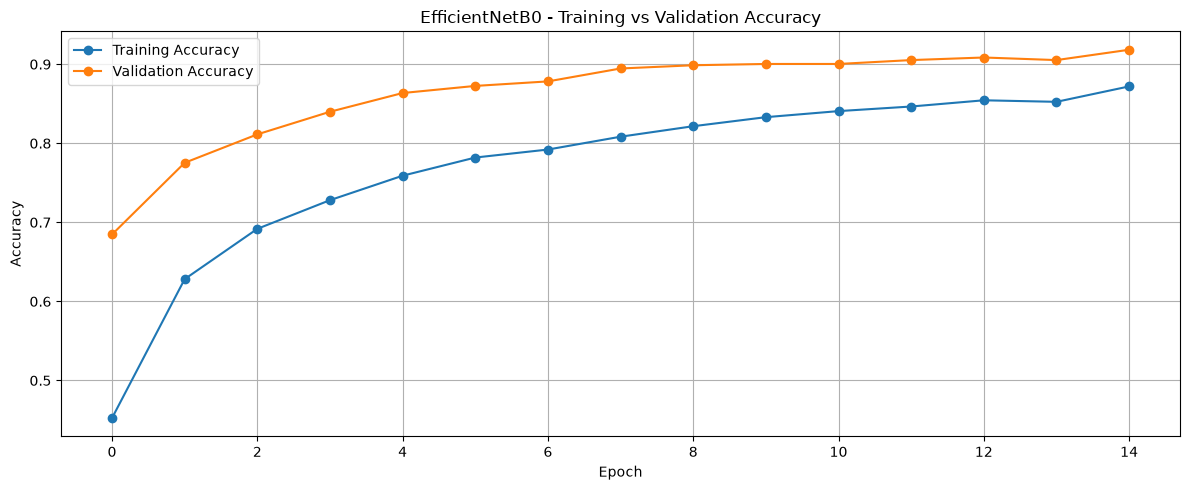

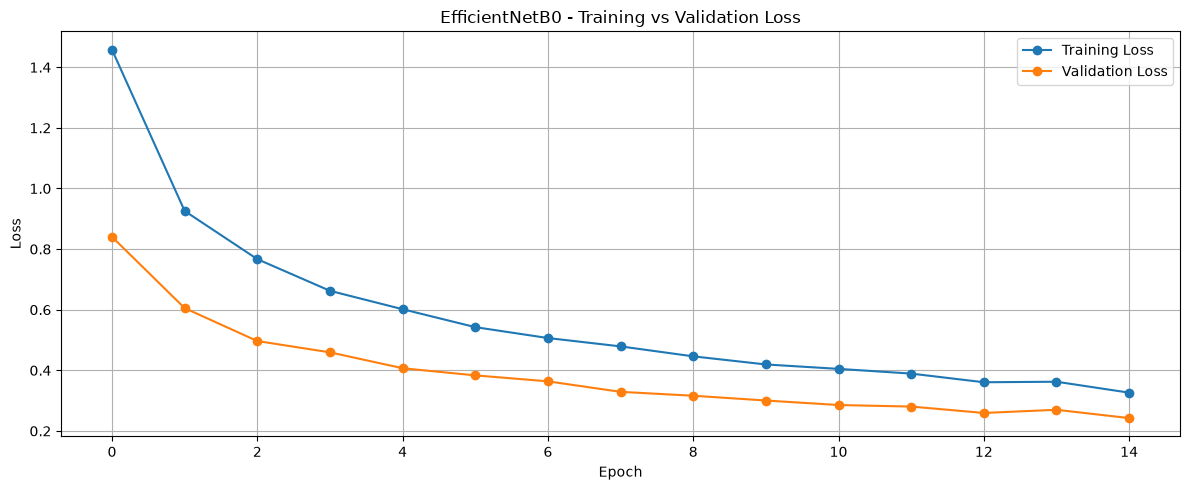

In [29]:
# ============================================================
# CELL 23 — EFFICIENTNET TRAINING GRAPHS
# ============================================================

import matplotlib.pyplot as plt

history = efficientnet_history.history

plt.figure(figsize=(12, 5))

plt.plot(
    history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("EfficientNetB0 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("EfficientNetB0 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# CELL 24 — EFFICIENTNETB0 TEST EVALUATION
# ============================================================

print("=" * 60)
print("EFFICIENTNETB0 — FINAL TEST EVALUATION")
print("=" * 60)

test_loss, test_accuracy = efficientnet_model.evaluate(
    efficientnet_test_data,
    verbose=1
)

print("\n" + "=" * 60)
print(f"TEST LOSS     : {test_loss:.4f}")
print(f"TEST ACCURACY : {test_accuracy * 100:.2f}%")
print("=" * 60)

EFFICIENTNETB0 — FINAL TEST EVALUATION
39/39 ━━━━━━━━━━━━━━━━━━━━ 24s 609ms/step - accuracy: 0.9077 - loss: 0.2389

TEST LOSS     : 0.2389
TEST ACCURACY : 90.77%


In [31]:
# ============================================================
# CELL 25 — EFFICIENTNETB0 FINE-TUNING
# ============================================================

print("=" * 60)
print("EFFICIENTNETB0 — FINE-TUNING")
print("=" * 60)

# ------------------------------------------------------------
# 1. Unfreeze the last 30 layers of EfficientNetB0
# ------------------------------------------------------------

base_model = efficientnet_model.layers[0]

base_model.trainable = True

# Freeze all layers first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
for layer in base_model.layers[-30:]:
    # Keep BatchNormalization layers frozen
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# ------------------------------------------------------------
# 2. Recompile with a very small learning rate
# ------------------------------------------------------------

efficientnet_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 3. Count trainable parameters
# ------------------------------------------------------------

trainable_params = sum(
    tf.keras.backend.count_params(weight)
    for weight in efficientnet_model.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(weight)
    for weight in efficientnet_model.non_trainable_weights
)

print("\nTrainable parameters    :", f"{trainable_params:,}")
print("Non-trainable parameters:", f"{non_trainable_params:,}")

# ------------------------------------------------------------
# 4. Fine-tuning callbacks
# ------------------------------------------------------------

finetune_checkpoint = ModelCheckpoint(
    "best_efficientnet_finetuned.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

finetune_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

finetune_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# ------------------------------------------------------------
# 5. Fine-tune the model
# ------------------------------------------------------------

finetune_history = efficientnet_model.fit(
    efficientnet_train_data,
    validation_data=efficientnet_validation_data,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        finetune_checkpoint,
        finetune_early_stopping,
        finetune_reduce_lr
    ],
    verbose=1
)

# ------------------------------------------------------------
# 6. Show best validation accuracy
# ------------------------------------------------------------

best_finetune_val_accuracy = max(
    finetune_history.history["val_accuracy"]
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 FINE-TUNING COMPLETED")
print("=" * 60)

print(
    f"Best Fine-Tuning Validation Accuracy: "
    f"{best_finetune_val_accuracy * 100:.2f}%"
)

EFFICIENTNETB0 — FINE-TUNING

Trainable parameters    : 1,815,398
Non-trainable parameters: 2,568,771
Epoch 1/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 960ms/step - accuracy: 0.8725 - loss: 0.3253
Epoch 1: val_accuracy improved from None to 0.91830, saving model to best_efficientnet_finetuned.keras

Epoch 1: finished saving model to best_efficientnet_finetuned.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 343s 1s/step - accuracy: 0.8725 - loss: 0.3253 - val_accuracy: 0.9183 - val_loss: 0.2321 - learning_rate: 1.0000e-05
Epoch 2/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 952ms/step - accuracy: 0.8825 - loss: 0.2962
Epoch 2: val_accuracy improved from 0.91830 to 0.92157, saving model to best_efficientnet_finetuned.keras

Epoch 2: finished saving model to best_efficientnet_finetuned.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 315s 1s/step - accuracy: 0.8825 - loss: 0.2962 - val_accuracy: 0.9216 - val_loss: 0.2212 - learning_rate: 1.0000e-05
Epoch 3/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 957ms/step - accuracy: 0.8845 - loss: 0.

In [32]:
# ============================================================
# CELL 26 — FINAL FINE-TUNED MODEL TEST EVALUATION
# ============================================================

print("=" * 60)
print("EFFICIENTNETB0 FINE-TUNED — FINAL TEST EVALUATION")
print("=" * 60)

# Load the best fine-tuned model
best_finetuned_model = tf.keras.models.load_model(
    "best_efficientnet_finetuned.keras"
)

# Evaluate on completely unseen test data
final_test_loss, final_test_accuracy = best_finetuned_model.evaluate(
    efficientnet_test_data,
    verbose=1
)

print("\n" + "=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Loss     : {final_test_loss:.4f}")
print(f"Test Accuracy : {final_test_accuracy * 100:.2f}%")
print("=" * 60)

EFFICIENTNETB0 FINE-TUNED — FINAL TEST EVALUATION
39/39 ━━━━━━━━━━━━━━━━━━━━ 30s 572ms/step - accuracy: 0.9469 - loss: 0.1581

FINAL TEST RESULTS
Test Loss     : 0.1581
Test Accuracy : 94.69%


In [33]:
# ============================================================
# CELL 27 — FINAL CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report
import numpy as np

print("=" * 70)
print("EFFICIENTNETB0 FINE-TUNED — CLASSIFICATION REPORT")
print("=" * 70)

# Reset test generator
efficientnet_test_data.reset()

# Get predictions
y_prob = best_finetuned_model.predict(
    efficientnet_test_data,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)
y_true = efficientnet_test_data.classes

# Classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print("\n" + report)

EFFICIENTNETB0 FINE-TUNED — CLASSIFICATION REPORT
39/39 ━━━━━━━━━━━━━━━━━━━━ 33s 698ms/step

                                  precision    recall  f1-score   support

                          a_Good     0.9615    0.9740    0.9677       154
                      b_Moderate     0.9423    0.9304    0.9363       158
c_Unhealthy_for_Sensitive_Groups     0.9258    0.9161    0.9209       286
                     d_Unhealthy     0.9294    0.9542    0.9416       262
                e_Very_Unhealthy     0.9718    0.9452    0.9583       219
                        f_Severe     0.9728    0.9862    0.9795       145

                        accuracy                         0.9469      1224
                       macro avg     0.9506    0.9510    0.9507      1224
                    weighted avg     0.9470    0.9469    0.9469      1224



EFFICIENTNETB0 FINE-TUNED — CONFUSION MATRIX


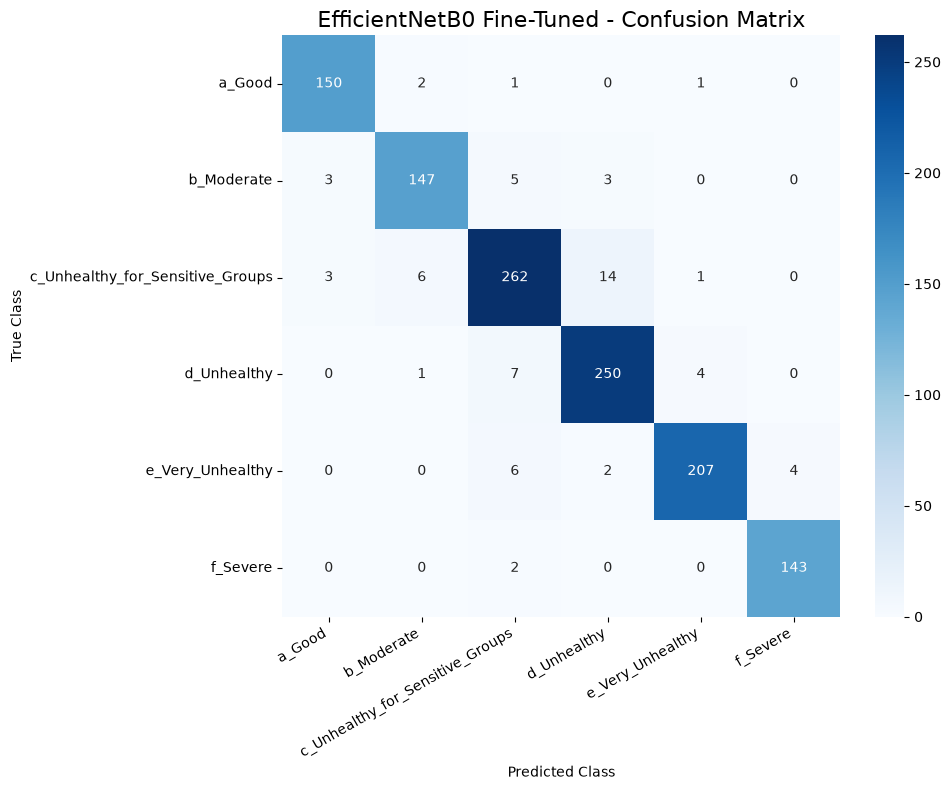

In [34]:
# ============================================================
# CELL 28 — FINAL CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("EFFICIENTNETB0 FINE-TUNED — CONFUSION MATRIX")
print("=" * 70)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 Fine-Tuned - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

MODEL PERFORMANCE COMPARISON


,Model,Validation Accuracy (%),Test Accuracy (%)
0,Custom CNN,78.02,78.10
1,EfficientNetB0 (Initial),91.83,90.77
2,EfficientNetB0 (Fine-Tuned),94.61,94.69


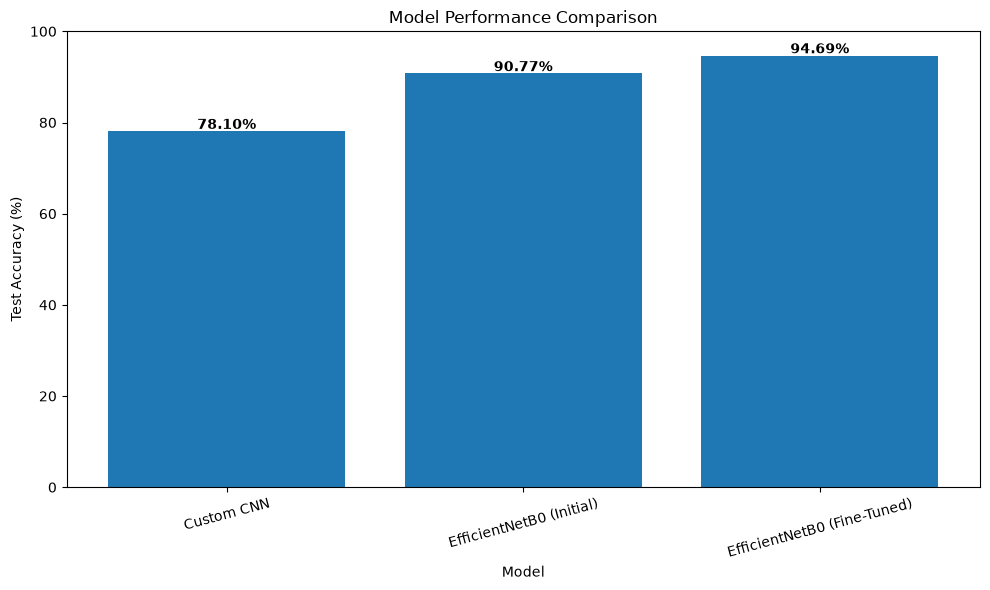

In [35]:
# ============================================================
# CELL 29 — MODEL PERFORMANCE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

comparison_df = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "EfficientNetB0 (Initial)",
        "EfficientNetB0 (Fine-Tuned)"
    ],
    "Validation Accuracy (%)": [
        max(cnn_history.history["val_accuracy"]) * 100,
        max(efficientnet_history.history["val_accuracy"]) * 100,
        max(finetune_history.history["val_accuracy"]) * 100
    ],
    "Test Accuracy (%)": [
        cnn_test_accuracy * 100,
        test_accuracy * 100,
        final_test_accuracy * 100
    ]
})

display(comparison_df.round(2))

# Accuracy comparison graph
plt.figure(figsize=(10, 6))

x = range(len(comparison_df))

plt.bar(
    x,
    comparison_df["Test Accuracy (%)"]
)

plt.xticks(x, comparison_df["Model"], rotation=15)
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Performance Comparison")

for i, value in enumerate(comparison_df["Test Accuracy (%)"]):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

SAMPLE IMAGE PREDICTION


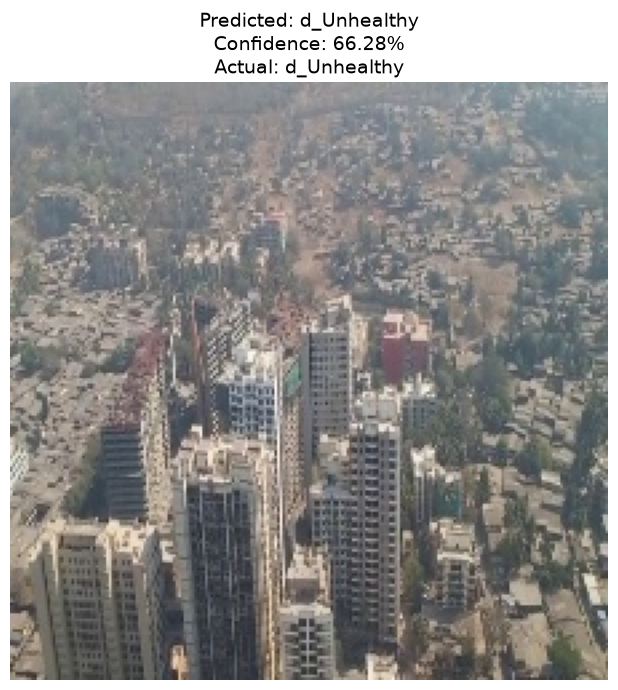

Image path       : air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Combined_Dataset\IND_and_NEP\d_Unhealthy\MH_UH_2023-02-10-14.30-1-82.jpg
Actual class     : d_Unhealthy
Predicted class  : d_Unhealthy
Confidence       : 66.28%


In [36]:
# ============================================================
# CELL 30 — SAMPLE IMAGE PREDICTION
# ============================================================

import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

print("=" * 70)
print("SAMPLE IMAGE PREDICTION")
print("=" * 70)

# Select a random image from the test dataset
sample_index = random.randrange(len(test_df))
sample_path = test_df.iloc[sample_index]["filepath"]
actual_label = test_df.iloc[sample_index]["label"]

# Load image
image = load_img(
    sample_path,
    target_size=IMG_SIZE
)

image_array = img_to_array(image) / 255.0
input_image = np.expand_dims(image_array, axis=0)

# Prediction
prediction = best_finetuned_model.predict(
    input_image,
    verbose=0
)

predicted_index = np.argmax(prediction[0])
predicted_label = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display image
plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%\n"
    f"Actual: {actual_label}",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Image path       :", sample_path)
print("Actual class     :", actual_label)
print("Predicted class  :", predicted_label)
print(f"Confidence       : {confidence:.2f}%")

GRAD-CAM EXPLAINABILITY
Base model: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM model created successfully.
Sample image: air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Combined_Dataset\IND_and_NEP\b_Moderate\Dimapur_MOD_2023-02-10-08.30-1-8.jpg
Actual class: b_Moderate


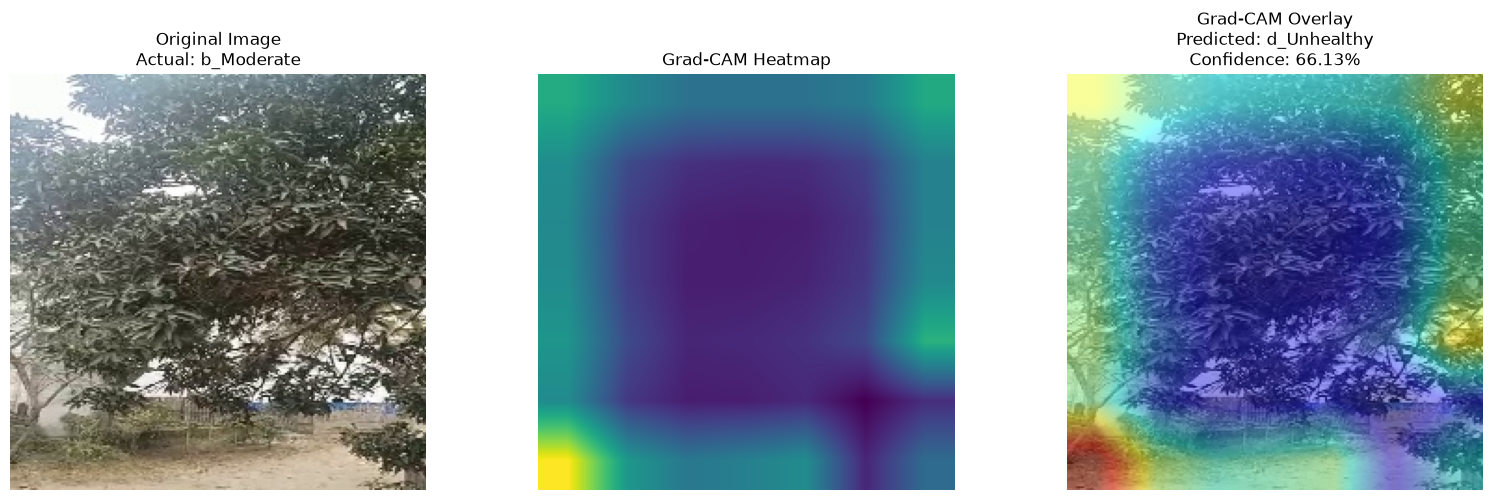


GRAD-CAM COMPLETED SUCCESSFULLY
Actual class    : b_Moderate
Predicted class : d_Unhealthy
Confidence      : 66.13%
Grad-CAM layer  : top_activation


In [12]:
# ============================================================
# CELL 31 — GRAD-CAM EXPLAINABILITY — FINAL FIX
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. GET EFFICIENTNETB0 BASE MODEL
# ------------------------------------------------------------

base_model = best_finetuned_model.layers[0]

print("Base model:", base_model.name)

# ------------------------------------------------------------
# 2. FIND LAST CONVOLUTIONAL LAYER INSIDE EFFICIENTNETB0
# ------------------------------------------------------------

conv_layer = None

for layer in reversed(base_model.layers):

    try:
        if len(layer.output.shape) == 4:
            conv_layer = layer
            break
    except Exception:
        continue

if conv_layer is None:
    raise ValueError(
        "No suitable convolutional layer found inside EfficientNetB0."
    )

print("Grad-CAM layer:", conv_layer.name)

# ------------------------------------------------------------
# 3. CREATE GRAD-CAM FUNCTIONAL GRAPH
# ------------------------------------------------------------

model_input = base_model.input

# Output from selected convolutional layer
conv_output = conv_layer.output

# Pass EfficientNet output through remaining classification layers
x = base_model.output

for layer in best_finetuned_model.layers[1:]:
    x = layer(x)

model_output = x

grad_model = tf.keras.models.Model(
    inputs=model_input,
    outputs=[conv_output, model_output]
)

print("Grad-CAM model created successfully.")

# ------------------------------------------------------------
# 4. GET SAMPLE IMAGE FROM TEST DATA
# ------------------------------------------------------------

sample_row = test_df.iloc[0]

sample_path = sample_row["filepath"]
actual_label = sample_row["label"]

print("Sample image:", sample_path)
print("Actual class:", actual_label)

# ------------------------------------------------------------
# 5. LOAD IMAGE
# ------------------------------------------------------------

img = tf.keras.utils.load_img(
    sample_path,
    target_size=IMG_SIZE
)

img_array = tf.keras.utils.img_to_array(img) / 255.0

input_tensor = np.expand_dims(
    img_array,
    axis=0
)

# ------------------------------------------------------------
# 6. GRADIENT CALCULATION
# ------------------------------------------------------------

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        input_tensor,
        training=False
    )

    predicted_class = tf.argmax(
        predictions[0]
    )

    class_score = predictions[:, predicted_class]

gradients = tape.gradient(
    class_score,
    conv_outputs
)

# ------------------------------------------------------------
# 7. GLOBAL AVERAGE POOLING
# ------------------------------------------------------------

pooled_gradients = tf.reduce_mean(
    gradients,
    axis=(0, 1, 2)
)

conv_outputs = conv_outputs[0]

# ------------------------------------------------------------
# 8. CREATE HEATMAP
# ------------------------------------------------------------

heatmap = conv_outputs @ pooled_gradients[..., tf.newaxis]

heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(
    heatmap,
    0
)

max_value = tf.reduce_max(heatmap)

if max_value > 0:
    heatmap = heatmap / max_value

heatmap = heatmap.numpy()

# ------------------------------------------------------------
# 9. RESIZE HEATMAP
# ------------------------------------------------------------

heatmap = cv2.resize(
    heatmap,
    (IMG_SIZE[1], IMG_SIZE[0])
)

# ------------------------------------------------------------
# 10. COLOR HEATMAP
# ------------------------------------------------------------

heatmap_uint8 = np.uint8(
    255 * heatmap
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# ------------------------------------------------------------
# 11. ORIGINAL IMAGE
# ------------------------------------------------------------

original_image = np.array(img).astype(np.uint8)

# ------------------------------------------------------------
# 12. OVERLAY
# ------------------------------------------------------------

overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_color,
    0.4,
    0
)

# ------------------------------------------------------------
# 13. PREDICTION DETAILS
# ------------------------------------------------------------

predicted_index = int(
    np.argmax(predictions.numpy()[0])
)

predicted_label = class_names[predicted_index]

confidence = float(
    predictions.numpy()[0][predicted_index] * 100
)

# ------------------------------------------------------------
# 14. DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)

plt.imshow(original_image)

plt.title(
    f"Original Image\n"
    f"Actual: {actual_label}"
)

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(heatmap)

plt.title(
    "Grad-CAM Heatmap"
)

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(overlay)

plt.title(
    f"Grad-CAM Overlay\n"
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 15. FINAL INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GRAD-CAM COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Actual class    :", actual_label)
print("Predicted class :", predicted_label)
print(f"Confidence      : {confidence:.2f}%")
print("Grad-CAM layer  :", conv_layer.name)

print("=" * 70)

In [13]:
# ============================================================
# CELL 32 — SAVE FINAL FINE-TUNED MODEL
# ============================================================

import os
import tensorflow as tf

print("=" * 70)
print("SAVING FINAL MODEL")
print("=" * 70)

FINAL_MODEL_PATH = "Air_Pollution_EfficientNetB0_Final.keras"

# Save the fine-tuned model
best_finetuned_model.save(FINAL_MODEL_PATH)

print("\n✅ FINAL MODEL SAVED SUCCESSFULLY!")
print("Model file:", FINAL_MODEL_PATH)

# Check file exists
if os.path.exists(FINAL_MODEL_PATH):
    file_size_mb = os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024)

    print(f"File size: {file_size_mb:.2f} MB")
    print("Status: READY FOR USE")

print("=" * 70)

SAVING FINAL MODEL

✅ FINAL MODEL SAVED SUCCESSFULLY!
Model file: Air_Pollution_EfficientNetB0_Final.keras
File size: 31.40 MB
Status: READY FOR USE


In [3]:
# ============================================================
# CELL 33 — RESNET50 TRANSFER LEARNING MODEL
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 70)
print("RESNET50 — TRANSFER LEARNING MODEL")
print("=" * 70)

# ------------------------------------------------------------
# 2. FIND DATASET FOLDER
# ------------------------------------------------------------

ROOT_DIR = "air_pollution_dataset"

dataset_path = None

for root, dirs, files in os.walk(ROOT_DIR):
    if "IND_and_NEP" in dirs:
        possible_path = os.path.join(root, "IND_and_NEP")

        class_folders = [
            folder
            for folder in os.listdir(possible_path)
            if os.path.isdir(os.path.join(possible_path, folder))
        ]

        if len(class_folders) >= 6:
            dataset_path = possible_path
            break

if dataset_path is None:
    raise FileNotFoundError(
        "❌ IND_and_NEP dataset folder not found. "
        "Please check that the dataset is extracted."
    )

print("\nDataset found:")
print(os.path.abspath(dataset_path))

# ------------------------------------------------------------
# 3. CREATE IMAGE DATAFRAME
# ------------------------------------------------------------

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

image_paths = []
labels = []

for class_name in sorted(class_folders):

    class_folder = os.path.join(
        dataset_path,
        class_name
    )

    for filename in os.listdir(class_folder):

        if filename.lower().endswith(IMAGE_EXTENSIONS):

            image_paths.append(
                os.path.join(
                    class_folder,
                    filename
                )
            )

            labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

# ------------------------------------------------------------
# 4. CLASS INFORMATION
# ------------------------------------------------------------

class_names = sorted(df["label"].unique())
NUM_CLASSES = len(class_names)

print("\nClasses:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("\nTotal images:", len(df))
print("Total classes:", NUM_CLASSES)

# ------------------------------------------------------------
# 5. TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("\n" + "=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))
print("Total images      :", len(df))

# ------------------------------------------------------------
# 6. RESNET50 DATA GENERATORS
# ------------------------------------------------------------

resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,

    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],

    fill_mode="nearest"
)

resnet_valid_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Training
resnet_train_data = resnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,

    x_col="filepath",
    y_col="label",

    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="categorical",
    classes=class_names,

    shuffle=True,
    seed=SEED
)

# Validation
resnet_validation_data = resnet_valid_test_datagen.flow_from_dataframe(
    dataframe=val_df,

    x_col="filepath",
    y_col="label",

    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="categorical",
    classes=class_names,

    shuffle=False
)

# Test
resnet_test_data = resnet_valid_test_datagen.flow_from_dataframe(
    dataframe=test_df,

    x_col="filepath",
    y_col="label",

    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="categorical",
    classes=class_names,

    shuffle=False
)

# ------------------------------------------------------------
# 7. LOAD RESNET50
# ------------------------------------------------------------

print("\nLoading ResNet50...")

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# ------------------------------------------------------------
# 8. BUILD RESNET50 CLASSIFIER
# ------------------------------------------------------------

resnet_model = models.Sequential([

    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dropout(0.40),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.30),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

], name="ResNet50_Air_Pollution_Classifier")

# ------------------------------------------------------------
# 9. COMPILE
# ------------------------------------------------------------

resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 10. FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET50 MODEL READY")
print("=" * 70)

print("Dataset images    :", len(df))
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))
print("Image size        :", IMG_SIZE)
print("Number of classes :", NUM_CLASSES)
print("Base model        :", resnet_base.name)

print("\nModel Summary:")
resnet_model.summary()

print("\n✅ ResNet50 model created successfully!")

RESNET50 — TRANSFER LEARNING MODEL

Dataset found:
C:\Users\shasw\air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Combined_Dataset\IND_and_NEP

Classes:
0: a_Good
1: b_Moderate
2: c_Unhealthy_for_Sensitive_Groups
3: d_Unhealthy
4: e_Very_Unhealthy
5: f_Severe

Total images: 12240
Total classes: 6

DATASET SPLIT
Training images   : 9792
Validation images : 1224
Testing images    : 1224
Total images      : 12240
Found 9792 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.
Found 1224 validated image filenames belonging to 6 classes.

Loading ResNet50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 34s 0us/step

RESNET50 MODEL READY
Dataset images    : 12240
Training images   : 9792
Validation images : 1224
Testing images    : 1224
Image size        : (224, 224)
Number of classes : 6
Base model        : resnet50

Model Summary:


Model: "ResNet50_Air_Pollution_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 2048)                │           8,192 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │           1,542 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,123,014 (92.02 MB)

 Trainable params: 530,694 (2.02 MB)

 Non-trainable params: 23,592,320 (90.00 MB)


✅ ResNet50 model created successfully!


In [5]:
# ============================================================
# RESNET50 — CLASS WEIGHTS
# ============================================================

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get class labels in the same order as class_names
class_indices = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

# Convert training labels to numeric values
train_numeric_labels = train_df["label"].map(class_indices).values

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_numeric_labels
)

# Create Keras-compatible dictionary
class_weights = {
    int(i): float(weight)
    for i, weight in enumerate(weights)
}

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

for i, class_name in enumerate(class_names):
    print(f"{class_name:40s} : {class_weights[i]:.4f}")

print("=" * 60)
print("✅ Class weights created successfully!")

CLASS WEIGHTS
a_Good                                   : 1.3236
b_Moderate                               : 1.2973
c_Unhealthy_for_Sensitive_Groups         : 0.7127
d_Unhealthy                              : 0.7779
e_Very_Unhealthy                         : 0.9299
f_Severe                                 : 1.4093
✅ Class weights created successfully!


In [6]:
# ============================================================
# CELL 34 — RESNET50 TRAINING
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("=" * 70)
print("RESNET50 — TRANSFER LEARNING TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------

resnet_checkpoint = ModelCheckpoint(
    "ResNet50_AirPollution_Best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

resnet_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

resnet_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

resnet_history = resnet_model.fit(
    resnet_train_data,
    validation_data=resnet_validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[
        resnet_checkpoint,
        resnet_early_stopping,
        resnet_reduce_lr
    ],
    verbose=1
)

# ------------------------------------------------------------
# Best validation accuracy
# ------------------------------------------------------------

best_resnet_val_accuracy = max(
    resnet_history.history["val_accuracy"]
)

print("\n" + "=" * 70)
print("RESNET50 TRAINING COMPLETED")
print("=" * 70)

print(
    f"Best Validation Accuracy: "
    f"{best_resnet_val_accuracy * 100:.2f}%"
)

print("=" * 70)

RESNET50 — TRANSFER LEARNING TRAINING
Epoch 1/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4470 - loss: 1.5398
Epoch 1: val_accuracy improved from None to 0.71078, saving model to ResNet50_AirPollution_Best.keras

Epoch 1: finished saving model to ResNet50_AirPollution_Best.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 416s 1s/step - accuracy: 0.4470 - loss: 1.5398 - val_accuracy: 0.7108 - val_loss: 0.7687 - learning_rate: 1.0000e-04
Epoch 2/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6080 - loss: 1.0213
Epoch 2: val_accuracy improved from 0.71078 to 0.78595, saving model to ResNet50_AirPollution_Best.keras

Epoch 2: finished saving model to ResNet50_AirPollution_Best.keras
306/306 ━━━━━━━━━━━━━━━━━━━━ 419s 1s/step - accuracy: 0.6080 - loss: 1.0213 - val_accuracy: 0.7859 - val_loss: 0.5639 - learning_rate: 1.0000e-04
Epoch 3/15
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6658 - loss: 0.8528
Epoch 3: val_accuracy improved from 0.78595 to 0.81699, saving model to 

RESNET50 — FINAL TEST EVALUATION
39/39 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step

RESNET50 FINAL TEST RESULTS
Test Accuracy : 92.32%

RESNET50 CLASSIFICATION REPORT
                                  precision    recall  f1-score   support

                          a_Good     0.8951    0.9416    0.9177       154
                      b_Moderate     0.9189    0.8608    0.8889       158
c_Unhealthy_for_Sensitive_Groups     0.9004    0.8846    0.8924       286
                     d_Unhealthy     0.9145    0.9389    0.9266       262
                e_Very_Unhealthy     0.9810    0.9406    0.9604       219
                        f_Severe     0.9351    0.9931    0.9632       145

                        accuracy                         0.9232      1224
                       macro avg     0.9241    0.9266    0.9249      1224
                    weighted avg     0.9236    0.9232    0.9230      1224



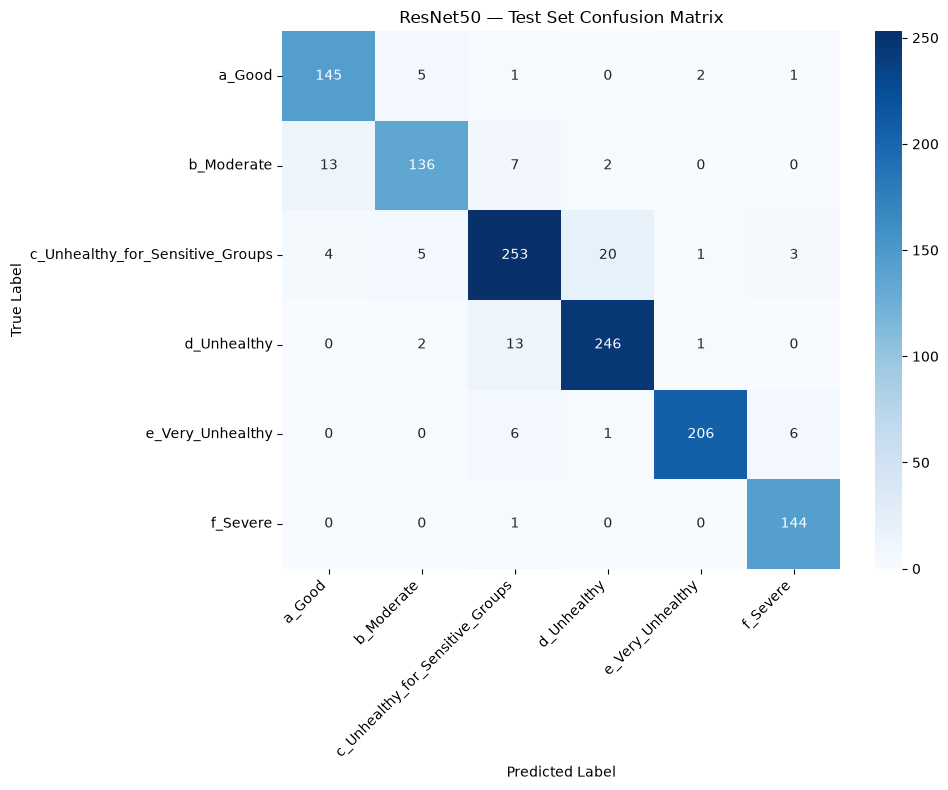


✅ ResNet50 test evaluation completed successfully!


In [7]:
# ============================================================
# CELL 35 — RESNET50 FINAL TEST EVALUATION
# ============================================================

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("RESNET50 — FINAL TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reset test generator
# ------------------------------------------------------------

resnet_test_data.reset()

# ------------------------------------------------------------
# 2. Predictions
# ------------------------------------------------------------

y_prob_resnet = resnet_model.predict(
    resnet_test_data,
    verbose=1
)

y_pred_resnet = np.argmax(
    y_prob_resnet,
    axis=1
)

y_true_resnet = resnet_test_data.classes

# ------------------------------------------------------------
# 3. Test accuracy
# ------------------------------------------------------------

resnet_test_accuracy = accuracy_score(
    y_true_resnet,
    y_pred_resnet
)

print("\n" + "=" * 70)
print("RESNET50 FINAL TEST RESULTS")
print("=" * 70)

print(
    f"Test Accuracy : "
    f"{resnet_test_accuracy * 100:.2f}%"
)

# ------------------------------------------------------------
# 4. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET50 CLASSIFICATION REPORT")
print("=" * 70)

resnet_report = classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names,
    digits=4
)

print(resnet_report)

# ------------------------------------------------------------
# 5. Confusion matrix
# ------------------------------------------------------------

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\n✅ ResNet50 test evaluation completed successfully!")

FINAL MODEL PERFORMANCE COMPARISON
         Model  Test Accuracy (%)
    Custom CNN          78.100000
EfficientNetB0          94.690000
      ResNet50          92.320261

BEST PERFORMING MODEL
Model   : EfficientNetB0
Accuracy: 94.69%


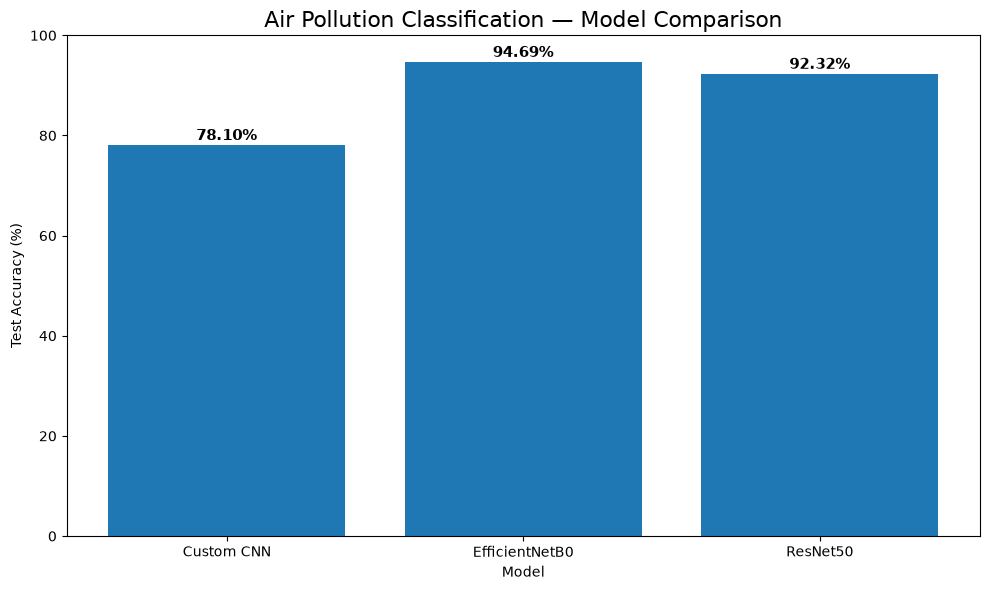


✅ Model comparison completed successfully!


In [8]:
# ============================================================
# CELL 36 — FINAL MODEL COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Final test accuracy values
# ------------------------------------------------------------

custom_cnn_accuracy = 78.10
efficientnet_accuracy = 94.69
resnet50_accuracy = resnet_test_accuracy * 100

# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "EfficientNetB0",
        "ResNet50"
    ],
    
    "Test Accuracy (%)": [
        custom_cnn_accuracy,
        efficientnet_accuracy,
        resnet50_accuracy
    ]
})

print("=" * 70)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 70)

print(comparison_df.to_string(index=False))

# ------------------------------------------------------------
# Best model
# ------------------------------------------------------------

best_model_row = comparison_df.loc[
    comparison_df["Test Accuracy (%)"].idxmax()
]

print("\n" + "=" * 70)
print("BEST PERFORMING MODEL")
print("=" * 70)

print(
    f"Model   : {best_model_row['Model']}"
)

print(
    f"Accuracy: "
    f"{best_model_row['Test Accuracy (%)']:.2f}%"
)

# ------------------------------------------------------------
# Accuracy comparison graph
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.title(
    "Air Pollution Classification — Model Comparison",
    fontsize=16
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)

for bar, value in zip(
    bars,
    comparison_df["Test Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

print("\n✅ Model comparison completed successfully!")

Grad-CAM target layer: top_activation


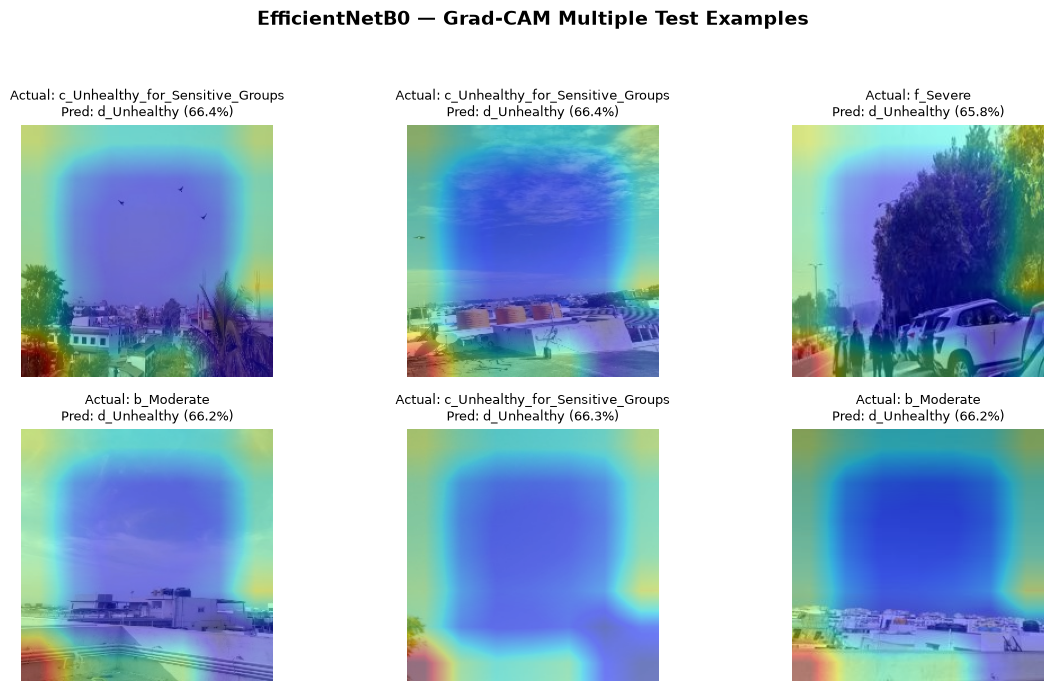


Grad-CAM examples generated: 6
Target layer: top_activation
Grad-CAM visualization completed successfully.


In [42]:
# ============================================================
# CELL 37 — MULTIPLE GRAD-CAM EXAMPLES
# FINAL FIXED + COMPACT VERSION
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image as keras_image


# ------------------------------------------------------------
# 1. LOAD FINAL EFFICIENTNET MODEL
# ------------------------------------------------------------

MODEL_PATH = "Air_Pollution_EfficientNetB0_Final.keras"

gradcam_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)


# ------------------------------------------------------------
# 2. IDENTIFY EFFICIENTNET BASE MODEL
# ------------------------------------------------------------

base_model = None
base_index = None

for i, layer in enumerate(gradcam_model.layers):

    if isinstance(layer, tf.keras.Model):
        base_model = layer
        base_index = i
        break


if base_model is None:
    raise ValueError(
        "EfficientNetB0 base model could not be found."
    )


# ------------------------------------------------------------
# 3. CALL COMPLETE MODEL ONCE
# ------------------------------------------------------------
# This ensures all nested layers have defined tensors.

dummy_input = tf.zeros(
    (1, 224, 224, 3),
    dtype=tf.float32
)

_ = gradcam_model(
    dummy_input,
    training=False
)


# ------------------------------------------------------------
# 4. FIND GRAD-CAM TARGET LAYER
# ------------------------------------------------------------

target_layer = None

try:
    target_layer = base_model.get_layer(
        "top_activation"
    )
except Exception:
    pass


# Fallback if top_activation is unavailable
if target_layer is None:

    for layer in reversed(base_model.layers):

        try:

            if len(layer.output.shape) == 4:
                target_layer = layer
                break

        except Exception:
            continue


if target_layer is None:
    raise ValueError(
        "Suitable Grad-CAM layer not found."
    )


# Make sure target layer is called
_ = base_model(dummy_input, training=False)


print(
    f"Grad-CAM target layer: {target_layer.name}"
)


# ------------------------------------------------------------
# 5. CREATE BASE GRADIENT MODEL
# ------------------------------------------------------------

feature_model = tf.keras.models.Model(
    inputs=base_model.input,
    outputs=[
        target_layer.output,
        base_model.output
    ]
)


# ------------------------------------------------------------
# 6. CREATE COMPLETE CLASSIFICATION HEAD
# ------------------------------------------------------------
# Everything after EfficientNetB0 in the original model
# is kept exactly as it was trained.

head_layers = gradcam_model.layers[
    base_index + 1:
]


# ------------------------------------------------------------
# 7. GRAD-CAM FUNCTION
# ------------------------------------------------------------

def generate_gradcam(img_path):

    # Load image
    img = keras_image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = keras_image.img_to_array(img)

    # Original image-only model used /255 preprocessing
    input_tensor = (
        np.expand_dims(
            img_array,
            axis=0
        ).astype("float32") / 255.0
    )


    # --------------------------------------------------------
    # Gradient calculation
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        conv_outputs, base_features = feature_model(
            input_tensor,
            training=False
        )

        x = base_features

        # Pass through the SAME classification head
        for layer in head_layers:

            x = layer(
                x,
                training=False
            )

        predictions = x

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[
            0,
            predicted_class
        ]


    # --------------------------------------------------------
    # Gradients
    # --------------------------------------------------------

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:
        raise ValueError(
            "Gradients are None. "
            "Grad-CAM connection failed."
        )


    # --------------------------------------------------------
    # Global average pooling
    # --------------------------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]


    # --------------------------------------------------------
    # Generate heatmap
    # --------------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )


    return (
        np.array(img),
        heatmap.numpy(),
        int(predicted_class),
        float(
            predictions[
                0,
                predicted_class
            ]
        )
    )


# ------------------------------------------------------------
# 8. SELECT 6 TEST IMAGES
# ------------------------------------------------------------

np.random.seed(42)

num_examples = min(
    6,
    len(X_test_paths)
)

selected_indices = np.random.choice(
    len(X_test_paths),
    size=num_examples,
    replace=False
)


# ------------------------------------------------------------
# 9. COMPACT 2 × 3 FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 7)
)

axes = axes.flatten()


# ------------------------------------------------------------
# 10. GENERATE GRAD-CAM EXAMPLES
# ------------------------------------------------------------

for plot_no, idx in enumerate(
    selected_indices
):

    img_path = X_test_paths[idx]

    (
        original_img,
        heatmap,
        pred_class,
        confidence
    ) = generate_gradcam(
        img_path
    )


    # Actual class
    actual_class = np.argmax(
        y_test_multi[idx]
    )

    actual_name = (
        label_encoder_multi
        .inverse_transform(
            [actual_class]
        )[0]
    )


    # Predicted class
    predicted_name = (
        label_encoder_multi
        .inverse_transform(
            [pred_class]
        )[0]
    )


    # Resize heatmap
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()


    # Original image
    axes[plot_no].imshow(
        original_img.astype("uint8")
    )


    # Grad-CAM overlay
    axes[plot_no].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.42
    )


    axes[plot_no].set_title(
        f"Actual: {actual_name}\n"
        f"Pred: {predicted_name} "
        f"({confidence * 100:.1f}%)",
        fontsize=9
    )

    axes[plot_no].axis("off")


# ------------------------------------------------------------
# 11. FINAL DISPLAY
# ------------------------------------------------------------

plt.suptitle(
    "EfficientNetB0 — Grad-CAM Multiple Test Examples",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()


# ------------------------------------------------------------
# 12. SHORT SUMMARY
# ------------------------------------------------------------

print(
    f"\nGrad-CAM examples generated: {num_examples}"
)

print(
    f"Target layer: {target_layer.name}"
)

print(
    "Grad-CAM visualization completed successfully."
)

In [19]:
# ============================================================
# CELL 38 — MULTIMODAL METADATA DISCOVERY
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("MULTIMODAL MODEL — METADATA DISCOVERY")
print("=" * 70)

# Search all CSV files
csv_files = []

for root, dirs, files in os.walk("air_pollution_dataset"):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(
                os.path.join(root, file)
            )

print("\nCSV files found:", len(csv_files))

for i, file in enumerate(csv_files, 1):
    print(f"{i}. {file}")

# ------------------------------------------------------------
# Find metadata CSV
# ------------------------------------------------------------

metadata_file = None

for file in csv_files:

    try:
        temp = pd.read_csv(
            file,
            nrows=5
        )

        cols = [
            str(c).strip().lower()
            for c in temp.columns
        ]

        required = [
            "filename",
            "aqi",
            "pm2.5",
            "pm10",
            "o3",
            "co",
            "so2",
            "no2",
            "aqi_class"
        ]

        matches = sum(
            col in cols
            for col in required
        )

        if matches >= 5:
            metadata_file = file
            break

    except Exception:
        pass


# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

if metadata_file is None:

    print("\n❌ Metadata CSV not found.")

else:

    print("\n" + "=" * 70)
    print("✅ METADATA FILE FOUND")
    print("=" * 70)

    print(
        "Path:",
        os.path.abspath(metadata_file)
    )

    metadata_df = pd.read_csv(
        metadata_file
    )

    print(
        "\nRows:",
        len(metadata_df)
    )

    print(
        "Columns:",
        len(metadata_df.columns)
    )

    print("\nAvailable columns:")

    for col in metadata_df.columns:
        print(" -", col)

    print("\nFirst 5 rows:")

    display(
        metadata_df.head()
    )

print("\n" + "=" * 70)
print("STEP COMPLETED")
print("=" * 70)

MULTIMODAL MODEL — METADATA DISCOVERY

CSV files found: 13
1. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Combined_Dataset\IND_and_Nep_AQI_Dataset.csv
2. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\India\Bengaluru\Bengaluru_AQI_All_info.csv
3. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\India\Delhi\Delhi_AQI_All_Info.csv
4. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\India\Dimapur\Dimapur_AQI_All_Info.csv
5. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\India\Faridabad\Faridabad_AQI_All_Info.csv
6. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\India\Greater_Noida\KPIII_UP_AQI_All.csv
7. air_pollution_dataset\Air Pollution Image Dataset\Air Pollution Image Dataset\Country_wise_Dataset\In

,Location,Filename,Year,Month,Day,Hour,AQI,PM2.5,PM10,O3,CO,SO2,NO2,AQI_Class
0,"Biratnagar, Nepal",BRI_Un_2023-02-02- 12.00-9.jpg,2023,2,2,12:00,158,70.08,100.82,58.89,0.49,4.4,1.04,d_Unhealthy
1,"Biratnagar, Nepal",BRI_Un_2023-02-02- 12.00-8.jpg,2023,2,2,12:00,158,70.08,100.82,58.89,0.49,4.4,1.04,d_Unhealthy
2,"Biratnagar, Nepal",BRI_Un_2023-02-02- 12.00-7.jpg,2023,2,2,12:00,158,70.08,100.82,58.89,0.49,4.4,1.04,d_Unhealthy
3,"Biratnagar, Nepal",BRI_Un_2023-02-02- 12.00-6.jpg,2023,2,2,12:00,158,70.08,100.82,58.89,0.49,4.4,1.04,d_Unhealthy
4,"Biratnagar, Nepal",BRI_Un_2023-02-02- 12.00-5.jpg,2023,2,2,12:00,158,70.08,100.82,58.89,0.49,4.4,1.04,d_Unhealthy



STEP COMPLETED


In [20]:
# ============================================================
# CELL 39 — IMAGE + ENVIRONMENTAL METADATA MERGE
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 80)
print("MULTIMODAL DATASET — IMAGE + METADATA MERGE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Create image dataframe
# ------------------------------------------------------------

image_records = []

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

for class_name in sorted(os.listdir(dataset_path)):

    class_folder = os.path.join(
        dataset_path,
        class_name
    )

    if not os.path.isdir(class_folder):
        continue

    for filename in os.listdir(class_folder):

        if filename.lower().endswith(IMAGE_EXTENSIONS):

            image_records.append({
                "filepath": os.path.join(
                    class_folder,
                    filename
                ),
                "Filename": filename,
                "image_label": class_name
            })


image_df = pd.DataFrame(
    image_records
)

print("\nImages found:", len(image_df))


# ------------------------------------------------------------
# 2. Clean filename columns
# ------------------------------------------------------------

image_df["Filename"] = (
    image_df["Filename"]
    .astype(str)
    .str.strip()
)

metadata_df["Filename"] = (
    metadata_df["Filename"]
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# 3. Check duplicate metadata filenames
# ------------------------------------------------------------

duplicate_metadata = (
    metadata_df["Filename"]
    .duplicated()
    .sum()
)

print(
    "Duplicate metadata filenames:",
    duplicate_metadata
)


# ------------------------------------------------------------
# 4. Remove duplicate metadata rows if any
# ------------------------------------------------------------

metadata_clean = (
    metadata_df
    .drop_duplicates(
        subset=["Filename"]
    )
    .copy()
)


# ------------------------------------------------------------
# 5. Merge image information with metadata
# ------------------------------------------------------------

multimodal_df = image_df.merge(
    metadata_clean,
    on="Filename",
    how="left"
)


# ------------------------------------------------------------
# 6. Merge quality check
# ------------------------------------------------------------

matched_count = (
    multimodal_df["AQI_Class"]
    .notna()
    .sum()
)

unmatched_count = (
    multimodal_df["AQI_Class"]
    .isna()
    .sum()
)

print("\n" + "=" * 80)
print("MERGE RESULTS")
print("=" * 80)

print(
    "Total image records     :",
    len(image_df)
)

print(
    "Metadata records        :",
    len(metadata_clean)
)

print(
    "Successfully matched    :",
    matched_count
)

print(
    "Unmatched images        :",
    unmatched_count
)


# ------------------------------------------------------------
# 7. Check label consistency
# ------------------------------------------------------------

if matched_count > 0:

    label_comparison = (
        multimodal_df[
            multimodal_df["AQI_Class"].notna()
        ]
        .copy()
    )

    label_comparison["label_match"] = (
        label_comparison["image_label"]
        ==
        label_comparison["AQI_Class"]
    )

    matching_labels = (
        label_comparison["label_match"]
        .sum()
    )

    mismatching_labels = (
        (~label_comparison["label_match"])
        .sum()
    )

    print("\n" + "=" * 80)
    print("LABEL CONSISTENCY CHECK")
    print("=" * 80)

    print(
        "Matching labels    :",
        matching_labels
    )

    print(
        "Mismatching labels :",
        mismatching_labels
    )


# ------------------------------------------------------------
# 8. Display important columns
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MULTIMODAL DATA SAMPLE")
print("=" * 80)

display(
    multimodal_df[
        [
            "filepath",
            "Filename",
            "image_label",
            "Location",
            "Year",
            "Month",
            "Day",
            "Hour",
            "AQI",
            "PM2.5",
            "PM10",
            "O3",
            "CO",
            "SO2",
            "NO2",
            "AQI_Class"
        ]
    ].head()
)


# ------------------------------------------------------------
# 9. Final merge validation
# ------------------------------------------------------------

if unmatched_count == 0:

    print("\n✅ All images successfully matched with metadata.")

else:

    print(
        f"\n⚠️ {unmatched_count} images "
        "could not be matched with metadata."
    )


# ------------------------------------------------------------
# 10. Save merged dataset
# ------------------------------------------------------------

multimodal_df.to_csv(
    "multimodal_air_pollution_dataset.csv",
    index=False
)

print(
    "\nSaved as:"
)

print(
    "multimodal_air_pollution_dataset.csv"
)

print("\n" + "=" * 80)
print("CELL 41 COMPLETED")
print("=" * 80)

MULTIMODAL DATASET — IMAGE + METADATA MERGE

Images found: 12240
Duplicate metadata filenames: 0

MERGE RESULTS
Total image records     : 12240
Metadata records        : 12240
Successfully matched    : 12240
Unmatched images        : 0

LABEL CONSISTENCY CHECK
Matching labels    : 12240
Mismatching labels : 0

MULTIMODAL DATA SAMPLE


,filepath,Filename,image_label,Location,Year,Month,Day,Hour,AQI,PM2.5,PM10,O3,CO,SO2,NO2,AQI_Class
0,air_pollution_dataset\Air Pollution Image Data...,BENGR_Good_2023-02-19-08.30-1-1.jpg,a_Good,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good
1,air_pollution_dataset\Air Pollution Image Data...,BENGR_Good_2023-02-19-08.30-1-10.jpg,a_Good,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good
2,air_pollution_dataset\Air Pollution Image Data...,BENGR_Good_2023-02-19-08.30-1-11.jpg,a_Good,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good
3,air_pollution_dataset\Air Pollution Image Data...,BENGR_Good_2023-02-19-08.30-1-12.jpg,a_Good,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good
4,air_pollution_dataset\Air Pollution Image Data...,BENGR_Good_2023-02-19-08.30-1-13.jpg,a_Good,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good



✅ All images successfully matched with metadata.

Saved as:
multimodal_air_pollution_dataset.csv

CELL 41 COMPLETED


In [21]:
# ============================================================
# CELL 40 — ENVIRONMENTAL FEATURE PREPARATION
# ============================================================

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

print("=" * 80)
print("MULTIMODAL MODEL — ENVIRONMENTAL FEATURE PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Features used by the multimodal model
# ------------------------------------------------------------
# AQI is intentionally excluded to avoid target leakage.
# AQI_Class is the prediction target.

environmental_features = [
    "PM2.5",
    "PM10",
    "O3",
    "CO",
    "SO2",
    "NO2"
]

target_column = "AQI_Class"

# ------------------------------------------------------------
# 2. Convert environmental columns to numeric
# ------------------------------------------------------------

for column in environmental_features:

    multimodal_df[column] = pd.to_numeric(
        multimodal_df[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. Check missing values
# ------------------------------------------------------------

print("\nMissing values before cleaning:")

print(
    multimodal_df[
        environmental_features
    ].isnull().sum()
)

# ------------------------------------------------------------
# 4. Remove rows with missing environmental data
# ------------------------------------------------------------

before_rows = len(multimodal_df)

multimodal_df = multimodal_df.dropna(
    subset=environmental_features + [target_column]
).copy()

after_rows = len(multimodal_df)

print("\nRows before cleaning :", before_rows)
print("Rows after cleaning  :", after_rows)
print("Rows removed         :", before_rows - after_rows)

# ------------------------------------------------------------
# 5. Check infinite values
# ------------------------------------------------------------

multimodal_df = multimodal_df.replace(
    [np.inf, -np.inf],
    np.nan
)

multimodal_df = multimodal_df.dropna(
    subset=environmental_features
).copy()

# ------------------------------------------------------------
# 6. Display feature statistics
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ENVIRONMENTAL FEATURE STATISTICS")
print("=" * 80)

display(
    multimodal_df[
        environmental_features
    ].describe()
)

# ------------------------------------------------------------
# 7. Standardize environmental features
# ------------------------------------------------------------

scaler = StandardScaler()

multimodal_df[
    environmental_features
] = scaler.fit_transform(
    multimodal_df[
        environmental_features
    ]
)

# ------------------------------------------------------------
# 8. Final check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NORMALIZATION CHECK")
print("=" * 80)

display(
    multimodal_df[
        environmental_features
    ].head()
)

print("\nFeature means after scaling:")

print(
    multimodal_df[
        environmental_features
    ].mean().round(4)
)

print("\nFeature standard deviations after scaling:")

print(
    multimodal_df[
        environmental_features
    ].std().round(4)
)

print("\n" + "=" * 80)
print("✅ ENVIRONMENTAL FEATURES READY")
print("=" * 80)

MULTIMODAL MODEL — ENVIRONMENTAL FEATURE PREPARATION

Missing values before cleaning:
PM2.5       0
PM10        0
O3        302
CO        580
SO2      1483
NO2       440
dtype: int64

Rows before cleaning : 12240
Rows after cleaning  : 10610
Rows removed         : 1630

ENVIRONMENTAL FEATURE STATISTICS


,PM2.5,PM10,O3,CO,SO2,NO2
count,10610.000000,10610.000000,10610.000000,10610.000000,10610.000000,10610.000000
mean,132.188108,139.443644,37.247923,106.643639,13.186552,31.811470
std,129.681394,107.182628,32.845773,119.748285,9.876863,34.156054
min,4.000000,7.000000,1.000000,0.250000,2.000000,0.670000
25%,33.180000,61.000000,10.000000,3.000000,4.400000,6.000000
50%,67.060000,100.820000,26.000000,52.000000,10.000000,18.000000
75%,193.000000,198.000000,58.890000,204.000000,20.000000,47.000000
max,500.000000,480.000000,225.000000,410.000000,48.000000,119.000000



NORMALIZATION CHECK


,PM2.5,PM10,O3,CO,SO2,NO2
0,-0.865146,-0.965161,-0.860058,0.487348,-1.031404,-0.69717
1,-0.865146,-0.965161,-0.860058,0.487348,-1.031404,-0.69717
2,-0.865146,-0.965161,-0.860058,0.487348,-1.031404,-0.69717
3,-0.865146,-0.965161,-0.860058,0.487348,-1.031404,-0.69717
4,-0.865146,-0.965161,-0.860058,0.487348,-1.031404,-0.69717



Feature means after scaling:
PM2.5    0.0
PM10     0.0
O3       0.0
CO       0.0
SO2     -0.0
NO2     -0.0
dtype: float64

Feature standard deviations after scaling:
PM2.5    1.0
PM10     1.0
O3       1.0
CO       1.0
SO2      1.0
NO2      1.0
dtype: float64

✅ ENVIRONMENTAL FEATURES READY


In [22]:
# ============================================================
# CELL 41 — MULTIMODAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

print("=" * 80)
print("MULTIMODAL DATASET — STRATIFIED SPLIT + SAFE SCALING")
print("=" * 80)

# ------------------------------------------------------------
# 1. Reset index
# ------------------------------------------------------------

multimodal_df = multimodal_df.reset_index(
    drop=True
)

# ------------------------------------------------------------
# 2. Required columns
# ------------------------------------------------------------

feature_columns = [
    "PM2.5",
    "PM10",
    "O3",
    "CO",
    "SO2",
    "NO2"
]

target_column = "AQI_Class"

# ------------------------------------------------------------
# 3. Remove rows with missing values
# ------------------------------------------------------------

multimodal_df = multimodal_df.dropna(
    subset=feature_columns + [target_column]
).copy()

print(
    "\nTotal usable records:",
    len(multimodal_df)
)

# ------------------------------------------------------------
# 4. 80% Train / 20% Temporary
# ------------------------------------------------------------

train_multi, temp_multi = train_test_split(
    multimodal_df,
    test_size=0.20,
    stratify=multimodal_df[target_column],
    random_state=42
)

# ------------------------------------------------------------
# 5. 10% Validation / 10% Test
# ------------------------------------------------------------

val_multi, test_multi = train_test_split(
    temp_multi,
    test_size=0.50,
    stratify=temp_multi[target_column],
    random_state=42
)

# ------------------------------------------------------------
# 6. Reset indexes
# ------------------------------------------------------------

train_multi = train_multi.reset_index(
    drop=True
)

val_multi = val_multi.reset_index(
    drop=True
)

test_multi = test_multi.reset_index(
    drop=True
)

# ------------------------------------------------------------
# 7. Print split sizes
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MULTIMODAL DATASET SPLIT")
print("=" * 80)

print(
    "Training records   :",
    len(train_multi)
)

print(
    "Validation records :",
    len(val_multi)
)

print(
    "Testing records    :",
    len(test_multi)
)

print(
    "Total records      :",
    len(train_multi)
    + len(val_multi)
    + len(test_multi)
)

# ------------------------------------------------------------
# 8. Show class distributions
# ------------------------------------------------------------

print("\nTraining distribution:")
print(
    train_multi[target_column]
    .value_counts()
)

print("\nValidation distribution:")
print(
    val_multi[target_column]
    .value_counts()
)

print("\nTesting distribution:")
print(
    test_multi[target_column]
    .value_counts()
)

# ------------------------------------------------------------
# 9. LEAKAGE-SAFE SCALING
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("LEAKAGE-SAFE FEATURE SCALING")
print("=" * 80)

scaler_multi = StandardScaler()

# Fit ONLY on training data
train_multi_features = scaler_multi.fit_transform(
    train_multi[feature_columns]
)

# Transform validation/test using training statistics
val_multi_features = scaler_multi.transform(
    val_multi[feature_columns]
)

test_multi_features = scaler_multi.transform(
    test_multi[feature_columns]
)

# ------------------------------------------------------------
# 10. Store scaled features
# ------------------------------------------------------------

train_multi_scaled = train_multi.copy()
val_multi_scaled = val_multi.copy()
test_multi_scaled = test_multi.copy()

train_multi_scaled[
    feature_columns
] = train_multi_features

val_multi_scaled[
    feature_columns
] = val_multi_features

test_multi_scaled[
    feature_columns
] = test_multi_features

# ------------------------------------------------------------
# 11. Final verification
# ------------------------------------------------------------

print("Scaler fitted ONLY on training data.")

print("\nTraining feature means:")
print(
    train_multi_scaled[
        feature_columns
    ].mean().round(4)
)

print("\nValidation feature means:")
print(
    val_multi_scaled[
        feature_columns
    ].mean().round(4)
)

print("\nTest feature means:")
print(
    test_multi_scaled[
        feature_columns
    ].mean().round(4)
)

print("\n" + "=" * 80)
print("✅ MULTIMODAL SPLIT + SAFE SCALING COMPLETED")
print("=" * 80)

MULTIMODAL DATASET — STRATIFIED SPLIT + SAFE SCALING

Total usable records: 10610

MULTIMODAL DATASET SPLIT
Training records   : 8488
Validation records : 1061
Testing records    : 1061
Total records      : 10610

Training distribution:
AQI_Class
c_Unhealthy_for_Sensitive_Groups    1891
d_Unhealthy                         1525
e_Very_Unhealthy                    1426
b_Moderate                          1258
a_Good                              1233
f_Severe                            1155
Name: count, dtype: int64

Validation distribution:
AQI_Class
c_Unhealthy_for_Sensitive_Groups    237
d_Unhealthy                         190
e_Very_Unhealthy                    179
b_Moderate                          157
a_Good                              154
f_Severe                            144
Name: count, dtype: int64

Testing distribution:
AQI_Class
c_Unhealthy_for_Sensitive_Groups    236
d_Unhealthy                         191
e_Very_Unhealthy                    178
b_Moderate                

In [23]:
# ============================================================
# CELL 42— MULTIMODAL INPUT PREPARATION
# ============================================================

from sklearn.preprocessing import LabelEncoder
import numpy as np
import tensorflow as tf

print("=" * 80)
print("MULTIMODAL MODEL — INPUT PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Label encoding
# ------------------------------------------------------------

label_encoder_multi = LabelEncoder()

label_encoder_multi.fit(
    multimodal_df[target_column]
)

train_labels_multi = label_encoder_multi.transform(
    train_multi_scaled[target_column]
)

val_labels_multi = label_encoder_multi.transform(
    val_multi_scaled[target_column]
)

test_labels_multi = label_encoder_multi.transform(
    test_multi_scaled[target_column]
)

NUM_CLASSES_MULTI = len(
    label_encoder_multi.classes_
)

print("\nClasses:")

for i, class_name in enumerate(
    label_encoder_multi.classes_
):
    print(f"{i} → {class_name}")

print(
    "\nNumber of classes:",
    NUM_CLASSES_MULTI
)


# ------------------------------------------------------------
# 2. Environmental feature arrays
# ------------------------------------------------------------

X_train_meta = train_multi_scaled[
    feature_columns
].values.astype("float32")

X_val_meta = val_multi_scaled[
    feature_columns
].values.astype("float32")

X_test_meta = test_multi_scaled[
    feature_columns
].values.astype("float32")


# ------------------------------------------------------------
# 3. Image paths
# ------------------------------------------------------------

X_train_paths = (
    train_multi_scaled["filepath"]
    .values
)

X_val_paths = (
    val_multi_scaled["filepath"]
    .values
)

X_test_paths = (
    test_multi_scaled["filepath"]
    .values
)


# ------------------------------------------------------------
# 4. Convert labels to one-hot
# ------------------------------------------------------------

y_train_multi = tf.keras.utils.to_categorical(
    train_labels_multi,
    num_classes=NUM_CLASSES_MULTI
)

y_val_multi = tf.keras.utils.to_categorical(
    val_labels_multi,
    num_classes=NUM_CLASSES_MULTI
)

y_test_multi = tf.keras.utils.to_categorical(
    test_labels_multi,
    num_classes=NUM_CLASSES_MULTI
)


# ------------------------------------------------------------
# 5. Verify shapes
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MULTIMODAL INPUT SHAPES")
print("=" * 80)

print(
    "Training images      :",
    X_train_paths.shape
)

print(
    "Training metadata    :",
    X_train_meta.shape
)

print(
    "Training labels      :",
    y_train_multi.shape
)

print(
    "\nValidation images    :",
    X_val_paths.shape
)

print(
    "Validation metadata  :",
    X_val_meta.shape
)

print(
    "Validation labels    :",
    y_val_multi.shape
)

print(
    "\nTesting images       :",
    X_test_paths.shape
)

print(
    "Testing metadata     :",
    X_test_meta.shape
)

print(
    "Testing labels       :",
    y_test_multi.shape
)


# ------------------------------------------------------------
# 6. Feature verification
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ENVIRONMENTAL FEATURES")
print("=" * 80)

for i, feature in enumerate(feature_columns):
    print(
        f"{i + 1}. {feature}"
    )


# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

assert len(X_train_paths) == len(X_train_meta)
assert len(X_train_paths) == len(y_train_multi)

assert len(X_val_paths) == len(X_val_meta)
assert len(X_val_paths) == len(y_val_multi)

assert len(X_test_paths) == len(X_test_meta)
assert len(X_test_paths) == len(y_test_multi)

print("\n" + "=" * 80)
print("✅ MULTIMODAL INPUT PREPARATION COMPLETED")
print("=" * 80)

MULTIMODAL MODEL — INPUT PREPARATION

Classes:
0 → a_Good
1 → b_Moderate
2 → c_Unhealthy_for_Sensitive_Groups
3 → d_Unhealthy
4 → e_Very_Unhealthy
5 → f_Severe

Number of classes: 6

MULTIMODAL INPUT SHAPES
Training images      : (8488,)
Training metadata    : (8488, 6)
Training labels      : (8488, 6)

Validation images    : (1061,)
Validation metadata  : (1061, 6)
Validation labels    : (1061, 6)

Testing images       : (1061,)
Testing metadata     : (1061, 6)
Testing labels       : (1061, 6)

ENVIRONMENTAL FEATURES
1. PM2.5
2. PM10
3. O3
4. CO
5. SO2
6. NO2

✅ MULTIMODAL INPUT PREPARATION COMPLETED


In [24]:
# ============================================================
# CELL 43 — MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

print("=" * 80)
print("MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL")
print("=" * 80)

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

IMAGE_SIZE = (224, 224, 3)
META_FEATURES = len(feature_columns)

print("\nImage input size      :", IMAGE_SIZE)
print("Environmental features:", META_FEATURES)
print("Number of classes     :", NUM_CLASSES_MULTI)

# ------------------------------------------------------------
# 2. IMAGE BRANCH
# ------------------------------------------------------------

image_input = layers.Input(
    shape=IMAGE_SIZE,
    name="image_input"
)

image_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=IMAGE_SIZE
)

# Freeze pretrained EfficientNet initially
image_base.trainable = False

image_features = image_base(
    image_input,
    training=False
)

image_features = layers.GlobalAveragePooling2D(
    name="image_global_pooling"
)(image_features)

image_features = layers.BatchNormalization(
    name="image_batch_norm"
)(image_features)

image_features = layers.Dropout(
    0.30,
    name="image_dropout"
)(image_features)

image_features = layers.Dense(
    256,
    activation="relu",
    name="image_dense"
)(image_features)

# ------------------------------------------------------------
# 3. ENVIRONMENTAL DATA BRANCH
# ------------------------------------------------------------

metadata_input = layers.Input(
    shape=(META_FEATURES,),
    name="environmental_input"
)

metadata_features = layers.Dense(
    64,
    activation="relu",
    name="metadata_dense_1"
)(metadata_input)

metadata_features = layers.BatchNormalization(
    name="metadata_batch_norm"
)(metadata_features)

metadata_features = layers.Dropout(
    0.20,
    name="metadata_dropout"
)(metadata_features)

metadata_features = layers.Dense(
    32,
    activation="relu",
    name="metadata_dense_2"
)(metadata_features)

# ------------------------------------------------------------
# 4. FUSION
# ------------------------------------------------------------

combined_features = layers.Concatenate(
    name="multimodal_fusion"
)([
    image_features,
    metadata_features
])

combined_features = layers.Dense(
    128,
    activation="relu",
    name="fusion_dense"
)(combined_features)

combined_features = layers.BatchNormalization(
    name="fusion_batch_norm"
)(combined_features)

combined_features = layers.Dropout(
    0.30,
    name="fusion_dropout"
)(combined_features)

# ------------------------------------------------------------
# 5. OUTPUT
# ------------------------------------------------------------

output = layers.Dense(
    NUM_CLASSES_MULTI,
    activation="softmax",
    name="pollution_class_output"
)(combined_features)

# ------------------------------------------------------------
# 6. CREATE MODEL
# ------------------------------------------------------------

multimodal_model = Model(
    inputs=[
        image_input,
        metadata_input
    ],
    outputs=output,
    name="Multimodal_EfficientNetB0_AirPollution"
)

# ------------------------------------------------------------
# 7. COMPILE
# ------------------------------------------------------------

multimodal_model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 8. MODEL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MULTIMODAL MODEL SUMMARY")
print("=" * 80)

multimodal_model.summary()

print("\n" + "=" * 80)
print("✅ MULTIMODAL MODEL CREATED SUCCESSFULLY")
print("=" * 80)

MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL

Image input size      : (224, 224, 3)
Environmental features: 6
Number of classes     : 6

MULTIMODAL MODEL SUMMARY


Model: "Multimodal_EfficientNetB0_AirPollution"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ efficientnetb0 (Functional)   │ (None, 7, 7, 1280)        │       4,049,571 │ image_input[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ environmental_input           │ (None, 6)                 │               0 │ -                          │
│ (InputLayer)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_global_pooling          │ (None, 1280)              │               0 │ efficientnetb0[0][0]       │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dense_1 (Dense)      │ (None, 64)                │             448 │ environmental_input[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_batch_norm              │ (None, 1280)              │           5,120 │ image_global_pooling[0][0] │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_batch_norm           │ (None, 64)                │             256 │ metadata_dense_1[0][0]     │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_dropout (Dropout)       │ (None, 1280)              │               0 │ image_batch_norm[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dropout (Dropout)    │ (None, 64)                │               0 │ metadata_batch_norm[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_dense (Dense)           │ (None, 256)               │         327,936 │ image_dropout[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dense_2 (Dense)      │ (None, 32)                │           2,080 │ metadata_dropout[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multimodal_fusion             │ (None, 288)               │               0 │ image_dense[0][0],         │
│ (Concatenate)                 │                           │                 │ metadata_dense_2[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense (Dense)          │ (None, 128)               │          36,992 │ multimodal_fusion[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_batch_norm             │ (None, 128)               │             512 │ fusion_dense[0][0]         │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 4,423,689 (16.88 MB)

 Trainable params: 371,174 (1.42 MB)

 Non-trainable params: 4,052,515 (15.46 MB)


✅ MULTIMODAL MODEL CREATED SUCCESSFULLY


In [25]:
# ============================================================
# CELL 44 — MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

print("=" * 80)
print("MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL")
print("=" * 80)

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

IMAGE_SIZE = (224, 224, 3)
META_FEATURES = len(feature_columns)

print("\nImage input size      :", IMAGE_SIZE)
print("Environmental features:", META_FEATURES)
print("Number of classes     :", NUM_CLASSES_MULTI)

# ------------------------------------------------------------
# 2. IMAGE BRANCH
# ------------------------------------------------------------

image_input = layers.Input(
    shape=IMAGE_SIZE,
    name="image_input"
)

image_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=IMAGE_SIZE
)

# Freeze pretrained EfficientNet initially
image_base.trainable = False

image_features = image_base(
    image_input,
    training=False
)

image_features = layers.GlobalAveragePooling2D(
    name="image_global_pooling"
)(image_features)

image_features = layers.BatchNormalization(
    name="image_batch_norm"
)(image_features)

image_features = layers.Dropout(
    0.30,
    name="image_dropout"
)(image_features)

image_features = layers.Dense(
    256,
    activation="relu",
    name="image_dense"
)(image_features)

# ------------------------------------------------------------
# 3. ENVIRONMENTAL DATA BRANCH
# ------------------------------------------------------------

metadata_input = layers.Input(
    shape=(META_FEATURES,),
    name="environmental_input"
)

metadata_features = layers.Dense(
    64,
    activation="relu",
    name="metadata_dense_1"
)(metadata_input)

metadata_features = layers.BatchNormalization(
    name="metadata_batch_norm"
)(metadata_features)

metadata_features = layers.Dropout(
    0.20,
    name="metadata_dropout"
)(metadata_features)

metadata_features = layers.Dense(
    32,
    activation="relu",
    name="metadata_dense_2"
)(metadata_features)

# ------------------------------------------------------------
# 4. FUSION
# ------------------------------------------------------------

combined_features = layers.Concatenate(
    name="multimodal_fusion"
)([
    image_features,
    metadata_features
])

combined_features = layers.Dense(
    128,
    activation="relu",
    name="fusion_dense"
)(combined_features)

combined_features = layers.BatchNormalization(
    name="fusion_batch_norm"
)(combined_features)

combined_features = layers.Dropout(
    0.30,
    name="fusion_dropout"
)(combined_features)

# ------------------------------------------------------------
# 5. OUTPUT
# ------------------------------------------------------------

output = layers.Dense(
    NUM_CLASSES_MULTI,
    activation="softmax",
    name="pollution_class_output"
)(combined_features)

# ------------------------------------------------------------
# 6. CREATE MODEL
# ------------------------------------------------------------

multimodal_model = Model(
    inputs=[
        image_input,
        metadata_input
    ],
    outputs=output,
    name="Multimodal_EfficientNetB0_AirPollution"
)

# ------------------------------------------------------------
# 7. COMPILE
# ------------------------------------------------------------

multimodal_model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 8. MODEL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MULTIMODAL MODEL SUMMARY")
print("=" * 80)

multimodal_model.summary()

print("\n" + "=" * 80)
print("✅ MULTIMODAL MODEL CREATED SUCCESSFULLY")
print("=" * 80)

MULTIMODAL EFFICIENTNETB0 + ENVIRONMENTAL MODEL

Image input size      : (224, 224, 3)
Environmental features: 6
Number of classes     : 6

MULTIMODAL MODEL SUMMARY


Model: "Multimodal_EfficientNetB0_AirPollution"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ efficientnetb0 (Functional)   │ (None, 7, 7, 1280)        │       4,049,571 │ image_input[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ environmental_input           │ (None, 6)                 │               0 │ -                          │
│ (InputLayer)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_global_pooling          │ (None, 1280)              │               0 │ efficientnetb0[0][0]       │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dense_1 (Dense)      │ (None, 64)                │             448 │ environmental_input[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_batch_norm              │ (None, 1280)              │           5,120 │ image_global_pooling[0][0] │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_batch_norm           │ (None, 64)                │             256 │ metadata_dense_1[0][0]     │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_dropout (Dropout)       │ (None, 1280)              │               0 │ image_batch_norm[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dropout (Dropout)    │ (None, 64)                │               0 │ metadata_batch_norm[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ image_dense (Dense)           │ (None, 256)               │         327,936 │ image_dropout[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ metadata_dense_2 (Dense)      │ (None, 32)                │           2,080 │ metadata_dropout[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multimodal_fusion             │ (None, 288)               │               0 │ image_dense[0][0],         │
│ (Concatenate)                 │                           │                 │ metadata_dense_2[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense (Dense)          │ (None, 128)               │          36,992 │ multimodal_fusion[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_batch_norm             │ (None, 128)               │             512 │ fusion_dense[0][0]         │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 4,423,689 (16.88 MB)

 Trainable params: 371,174 (1.42 MB)

 Non-trainable params: 4,052,515 (15.46 MB)


✅ MULTIMODAL MODEL CREATED SUCCESSFULLY


In [26]:
# ============================================================
# CELL 45— MULTIMODAL DATA PIPELINE
# Image + Environmental Metadata
# ============================================================

import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("=" * 70)
print("CREATING MULTIMODAL DATA PIPELINE")
print("=" * 70)


# ------------------------------------------------------------
# 1. IMAGE LOADING FUNCTION
# ------------------------------------------------------------

def load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    
    # Keep pixel values in 0-255 range.
    # Keras EfficientNetB0 contains its own input rescaling.
    image = tf.cast(image, tf.float32)
    
    return image


# ------------------------------------------------------------
# 2. TRAINING PREPROCESSING + AUGMENTATION
# ------------------------------------------------------------

def preprocess_train(image_path, metadata, label):
    
    image = load_image(image_path)
    
    # Data augmentation ONLY for training
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.08)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    
    # Keep valid image range
    image = tf.clip_by_value(image, 0.0, 255.0)
    
    return {
        "image_input": image,
        "metadata_input": metadata
    }, label


# ------------------------------------------------------------
# 3. VALIDATION / TEST PREPROCESSING
# ------------------------------------------------------------

def preprocess_eval(image_path, metadata, label):
    
    image = load_image(image_path)
    
    return {
        "image_input": image,
        "metadata_input": metadata
    }, label


# ------------------------------------------------------------
# 4. CREATE TRAIN DATASET
# ------------------------------------------------------------

train_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_train_paths,
        X_train_meta.astype(np.float32),
        y_train_multi.astype(np.float32)
    )
)

train_ds = (
    train_ds
    .shuffle(
        buffer_size=len(X_train_paths),
        reshuffle_each_iteration=True
    )
    .map(preprocess_train, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ------------------------------------------------------------
# 5. CREATE VALIDATION DATASET
# ------------------------------------------------------------

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_val_paths,
        X_val_meta.astype(np.float32),
        y_val_multi.astype(np.float32)
    )
)

val_ds = (
    val_ds
    .map(preprocess_eval, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ------------------------------------------------------------
# 6. CREATE TEST DATASET
# ------------------------------------------------------------

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_test_paths,
        X_test_meta.astype(np.float32),
        y_test_multi.astype(np.float32)
    )
)

test_ds = (
    test_ds
    .map(preprocess_eval, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ------------------------------------------------------------
# 7. VERIFY DATASET
# ------------------------------------------------------------

print("\nDataset sizes:")
print(f"Train samples      : {len(X_train_paths):,}")
print(f"Validation samples : {len(X_val_paths):,}")
print(f"Test samples       : {len(X_test_paths):,}")

print("\nBatch size          :", BATCH_SIZE)
print("Image size          :", IMG_SIZE)
print("Metadata features   :", X_train_meta.shape[1])
print("Number of classes   :", y_train_multi.shape[1])


# ------------------------------------------------------------
# 8. TEST ONE BATCH
# ------------------------------------------------------------

sample_batch = next(iter(train_ds))

sample_inputs, sample_labels = sample_batch

print("\nBatch verification:")
print("Image batch shape   :", sample_inputs["image_input"].shape)
print("Metadata batch shape:", sample_inputs["metadata_input"].shape)
print("Labels batch shape  :", sample_labels.shape)

# Assertions
assert sample_inputs["image_input"].shape[1:] == (224, 224, 3)
assert sample_inputs["metadata_input"].shape[1] == 6
assert sample_labels.shape[1] == 6

print("\n" + "=" * 70)
print("✅ MULTIMODAL DATA PIPELINE CREATED SUCCESSFULLY")
print("=" * 70)

CREATING MULTIMODAL DATA PIPELINE

Dataset sizes:
Train samples      : 8,488
Validation samples : 1,061
Test samples       : 1,061

Batch size          : 32
Image size          : (224, 224)
Metadata features   : 6
Number of classes   : 6

Batch verification:
Image batch shape   : (32, 224, 224, 3)
Metadata batch shape: (32, 6)
Labels batch shape  : (32, 6)

✅ MULTIMODAL DATA PIPELINE CREATED SUCCESSFULLY


In [27]:
# ============================================================
# CELL 46 — MULTIMODAL CLASS WEIGHTS
# ============================================================

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

print("=" * 70)
print("CALCULATING CLASS WEIGHTS")
print("=" * 70)

# Convert one-hot labels back to class indices
train_class_indices = np.argmax(y_train_multi, axis=1)

# Calculate balanced class weights using TRAINING DATA ONLY
classes = np.unique(train_class_indices)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_class_indices
)

multimodal_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("\nClass weights:")
for cls, weight in multimodal_class_weights.items():
    class_name = label_encoder_multi.inverse_transform([cls])[0]
    print(f"{cls} | {class_name:<40} | {weight:.4f}")

print("\n" + "=" * 70)
print("TRAINING SET CLASS DISTRIBUTION")
print("=" * 70)

unique_classes, counts = np.unique(
    train_class_indices,
    return_counts=True
)

for cls, count in zip(unique_classes, counts):
    class_name = label_encoder_multi.inverse_transform([cls])[0]
    print(f"{cls} | {class_name:<40} | {count:,}")

print("\n" + "=" * 70)
print("✅ CLASS WEIGHTS CALCULATED SUCCESSFULLY")
print("=" * 70)

CALCULATING CLASS WEIGHTS

Class weights:
0 | a_Good                                   | 1.1473
1 | b_Moderate                               | 1.1245
2 | c_Unhealthy_for_Sensitive_Groups         | 0.7481
3 | d_Unhealthy                              | 0.9277
4 | e_Very_Unhealthy                         | 0.9921
5 | f_Severe                                 | 1.2248

TRAINING SET CLASS DISTRIBUTION
0 | a_Good                                   | 1,233
1 | b_Moderate                               | 1,258
2 | c_Unhealthy_for_Sensitive_Groups         | 1,891
3 | d_Unhealthy                              | 1,525
4 | e_Very_Unhealthy                         | 1,426
5 | f_Severe                                 | 1,155

✅ CLASS WEIGHTS CALCULATED SUCCESSFULLY


In [30]:
# ============================================================
# CELL 47 — FIXED MULTIMODAL TRAINING v2
# Avoid input-name mismatch by using positional inputs
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 70)
print("STARTING MULTIMODAL EFFICIENTNETB0 TRAINING")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK MODEL INPUTS
# ------------------------------------------------------------

print("\nModel input information:")

for i, inp in enumerate(multimodal_model.inputs):
    print(
        f"Input {i}: "
        f"name={inp.name}, "
        f"shape={inp.shape}"
    )


# ------------------------------------------------------------
# 2. CONVERT DICTIONARY INPUTS TO POSITIONAL INPUTS
# ------------------------------------------------------------
# The model has:
# Input 0 -> image
# Input 1 -> metadata
#
# Using positional tuples avoids input-name mismatch.


def convert_train_batch(inputs, labels, sample_weights):
    
    image = inputs["image_input"]
    metadata = inputs["metadata_input"]
    
    return (
        (image, metadata),
        labels,
        sample_weights
    )


def convert_eval_batch(inputs, labels):
    
    image = inputs["image_input"]
    metadata = inputs["metadata_input"]
    
    return (
        (image, metadata),
        labels
    )


# ------------------------------------------------------------
# 3. CREATE WEIGHTED TRAIN DATASET
# ------------------------------------------------------------

class_weight_tensor = tf.constant(
    [
        multimodal_class_weights[i]
        for i in range(len(multimodal_class_weights))
    ],
    dtype=tf.float32
)


def add_sample_weights(inputs, labels):

    class_indices = tf.argmax(
        labels,
        axis=1,
        output_type=tf.int32
    )

    sample_weights = tf.gather(
        class_weight_tensor,
        class_indices
    )

    return inputs, labels, sample_weights


train_ds_weighted = (
    train_ds
    .map(
        add_sample_weights,
        num_parallel_calls=AUTOTUNE
    )
    .map(
        convert_train_batch,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)


# ------------------------------------------------------------
# 4. CONVERT VALIDATION DATASET
# ------------------------------------------------------------

val_ds_tuple = (
    val_ds
    .map(
        convert_eval_batch,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)


# ------------------------------------------------------------
# 5. VERIFY ONE TRAINING BATCH
# ------------------------------------------------------------

print("\nChecking training batch...")

sample_inputs, sample_labels, sample_weights = next(
    iter(train_ds_weighted)
)

print(
    "Image shape       :",
    sample_inputs[0].shape
)

print(
    "Metadata shape    :",
    sample_inputs[1].shape
)

print(
    "Labels shape      :",
    sample_labels.shape
)

print(
    "Sample weights    :",
    sample_weights.shape
)


# ------------------------------------------------------------
# 6. COMPILE MODEL
# ------------------------------------------------------------

multimodal_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n✅ Model compiled successfully")


# ------------------------------------------------------------
# 7. CALLBACKS
# ------------------------------------------------------------

multimodal_checkpoint_path = (
    "Multimodal_EfficientNetB0_Best.keras"
)

multimodal_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=multimodal_checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]


# ------------------------------------------------------------
# 8. TRAIN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING STARTED")
print("=" * 70)

multimodal_history = multimodal_model.fit(
    train_ds_weighted,
    validation_data=val_ds_tuple,
    epochs=15,
    callbacks=multimodal_callbacks,
    verbose=1
)


# ------------------------------------------------------------
# 9. BEST VALIDATION RESULT
# ------------------------------------------------------------

best_val_accuracy = max(
    multimodal_history.history["val_accuracy"]
)

best_val_epoch = (
    np.argmax(
        multimodal_history.history["val_accuracy"]
    ) + 1
)


print("\n" + "=" * 70)
print("✅ MULTIMODAL TRAINING COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    f"Best Validation Accuracy : "
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    f"Best Validation Epoch    : "
    f"{best_val_epoch}"
)

print(
    f"Best Model Saved At      : "
    f"{multimodal_checkpoint_path}"
)

print("=" * 70)

STARTING MULTIMODAL EFFICIENTNETB0 TRAINING

Model input information:
Input 0: name=image_input, shape=(None, 224, 224, 3)
Input 1: name=environmental_input, shape=(None, 6)

Checking training batch...
Image shape       : (32, 224, 224, 3)
Metadata shape    : (32, 6)
Labels shape      : (32, 6)
Sample weights    : (32,)

✅ Model compiled successfully

TRAINING STARTED
Epoch 1/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 0s 597ms/step - accuracy: 0.5005 - loss: 1.3467
Epoch 1: val_accuracy improved from None to 0.68238, saving model to Multimodal_EfficientNetB0_Best.keras

Epoch 1: finished saving model to Multimodal_EfficientNetB0_Best.keras
266/266 ━━━━━━━━━━━━━━━━━━━━ 203s 686ms/step - accuracy: 0.5005 - loss: 1.3467 - val_accuracy: 0.6824 - val_loss: 0.8646 - learning_rate: 1.0000e-04
Epoch 2/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.7092 - loss: 0.7400
Epoch 2: val_accuracy improved from 0.68238 to 0.87653, saving model to Multimodal_EfficientNetB0_Best.keras

Epoch 2: finishe

MULTIMODAL MODEL — FINAL TEST EVALUATION

✅ Best multimodal model loaded successfully
✅ Test dataset prepared

Generating predictions on untouched test set...
34/34 ━━━━━━━━━━━━━━━━━━━━ 28s 714ms/step
✅ Predictions generated

FINAL MULTIMODAL TEST RESULTS
Test Accuracy       : 99.43%
Macro F1-Score      : 99.36%
Weighted F1-Score   : 99.43%
Test Samples        : 1,061

CLASSIFICATION REPORT
                                  precision    recall  f1-score   support

                          a_Good     0.9745    0.9935    0.9839       154
                      b_Moderate     0.9935    0.9747    0.9840       158
c_Unhealthy_for_Sensitive_Groups     1.0000    1.0000    1.0000       236
                     d_Unhealthy     1.0000    1.0000    1.0000       191
                e_Very_Unhealthy     1.0000    0.9944    0.9972       178
                        f_Severe     0.9931    1.0000    0.9965       144

                        accuracy                         0.9943      1061
            

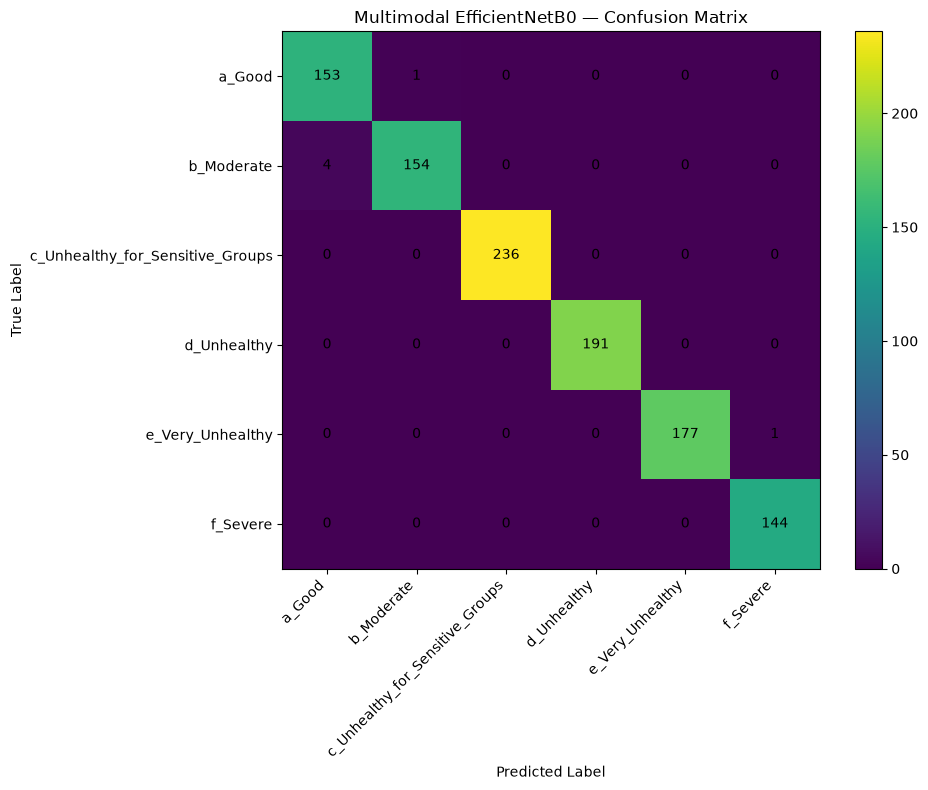


✅ MULTIMODAL TEST EVALUATION COMPLETED


In [31]:
# ============================================================
# CELL 48— MULTIMODAL FINAL TEST EVALUATION
# Accuracy + Macro F1 + Weighted F1
# Classification Report + Confusion Matrix
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("=" * 70)
print("MULTIMODAL MODEL — FINAL TEST EVALUATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. LOAD BEST MULTIMODAL MODEL
# ------------------------------------------------------------

best_multimodal_model = tf.keras.models.load_model(
    "Multimodal_EfficientNetB0_Best.keras",
    compile=False
)

print("\n✅ Best multimodal model loaded successfully")


# ------------------------------------------------------------
# 2. CONVERT TEST DATASET TO POSITIONAL INPUTS
# ------------------------------------------------------------

def convert_test_batch(inputs, labels):

    image = inputs["image_input"]
    metadata = inputs["metadata_input"]

    return (
        (image, metadata),
        labels
    )


test_ds_tuple = (
    test_ds
    .map(
        convert_test_batch,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

print("✅ Test dataset prepared")


# ------------------------------------------------------------
# 3. GENERATE PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating predictions on untouched test set...")

y_probability = best_multimodal_model.predict(
    test_ds_tuple,
    verbose=1
)

y_pred_multi = np.argmax(
    y_probability,
    axis=1
)

y_true_multi = np.argmax(
    y_test_multi,
    axis=1
)

print("✅ Predictions generated")


# ------------------------------------------------------------
# 4. TEST ACCURACY
# ------------------------------------------------------------

multimodal_test_accuracy = accuracy_score(
    y_true_multi,
    y_pred_multi
)


# ------------------------------------------------------------
# 5. F1 SCORES
# ------------------------------------------------------------

multimodal_macro_f1 = f1_score(
    y_true_multi,
    y_pred_multi,
    average="macro"
)

multimodal_weighted_f1 = f1_score(
    y_true_multi,
    y_pred_multi,
    average="weighted"
)


# ------------------------------------------------------------
# 6. FINAL TEST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL MULTIMODAL TEST RESULTS")
print("=" * 70)

print(
    f"Test Accuracy       : "
    f"{multimodal_test_accuracy * 100:.2f}%"
)

print(
    f"Macro F1-Score      : "
    f"{multimodal_macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1-Score   : "
    f"{multimodal_weighted_f1 * 100:.2f}%"
)

print(
    f"Test Samples        : "
    f"{len(y_true_multi):,}"
)


# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names_multi = list(
    label_encoder_multi.classes_
)

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true_multi,
        y_pred_multi,
        target_names=class_names_multi,
        digits=4
    )
)


# ------------------------------------------------------------
# 8. CONFUSION MATRIX
# ------------------------------------------------------------

cm_multi = confusion_matrix(
    y_true_multi,
    y_pred_multi
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_multi,
    interpolation="nearest"
)

plt.title(
    "Multimodal EfficientNetB0 — Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    range(len(class_names_multi)),
    class_names_multi,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(class_names_multi)),
    class_names_multi
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Numbers inside confusion matrix
for i in range(cm_multi.shape[0]):
    for j in range(cm_multi.shape[1]):
        plt.text(
            j,
            i,
            cm_multi[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ MULTIMODAL TEST EVALUATION COMPLETED")
print("=" * 70)

FINAL MODEL PERFORMANCE COMPARISON




,Model,Test Accuracy (%),Macro F1 (%),Weighted F1 (%)
0,Custom CNN,78.10,NaN,NaN
1,EfficientNetB0,94.69,95.07,94.69
2,ResNet50,92.32,92.49,92.30
3,Multimodal EfficientNetB0,99.43,99.36,99.43


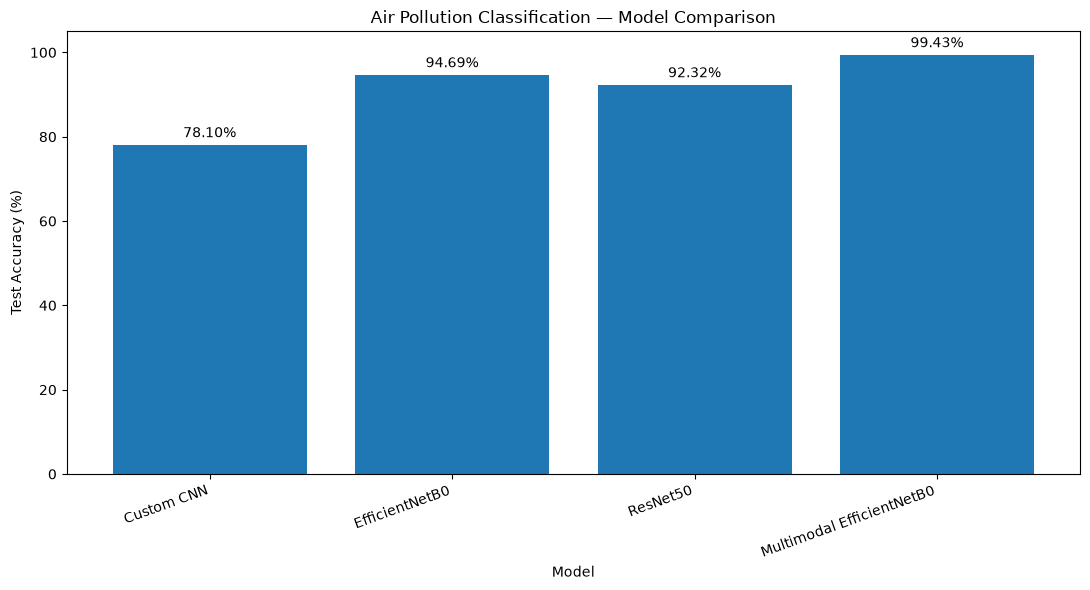


FINAL MULTIMODAL RESULT
Test Accuracy     : 99.43%
Macro F1-Score    : 99.36%
Weighted F1-Score : 99.43%
Test Samples      : 1,061
✅ FINAL MODEL COMPARISON COMPLETED


In [32]:
# ============================================================
# CELL 49 — FINAL MODEL COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

print("=" * 75)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

# Results already obtained from previous experiments
comparison_data = {
    "Model": [
        "Custom CNN",
        "EfficientNetB0",
        "ResNet50",
        "Multimodal EfficientNetB0"
    ],
    
    "Test Accuracy (%)": [
        78.10,
        94.69,
        92.32,
        multimodal_test_accuracy * 100
    ],
    
    "Macro F1 (%)": [
        None,
        95.07,
        92.49,
        multimodal_macro_f1 * 100
    ],
    
    "Weighted F1 (%)": [
        None,
        94.69,
        92.30,
        multimodal_weighted_f1 * 100
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("\n")
display(
    comparison_df.round(2)
)


# ------------------------------------------------------------
# ACCURACY COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.title(
    "Air Pollution Classification — Model Comparison"
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 105)

plt.xticks(
    rotation=20,
    ha="right"
)

# Display accuracy values
for bar, value in zip(
    bars,
    comparison_df["Test Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FINAL MULTIMODAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL MULTIMODAL RESULT")
print("=" * 75)

print(
    f"Test Accuracy     : "
    f"{multimodal_test_accuracy * 100:.2f}%"
)

print(
    f"Macro F1-Score    : "
    f"{multimodal_macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1-Score : "
    f"{multimodal_weighted_f1 * 100:.2f}%"
)

print(
    f"Test Samples      : "
    f"{len(y_true_multi):,}"
)

print("=" * 75)
print("✅ FINAL MODEL COMPARISON COMPLETED")
print("=" * 75)

In [35]:
# ============================================================
# CELL 50 — COMPLETE FINAL PROJECT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("          AIR POLLUTION CLASSIFICATION PROJECT")
print("                 COMPLETE FINAL SUMMARY")
print("=" * 80)

# ------------------------------------------------------------
# 1. PROJECT INFORMATION
# ------------------------------------------------------------

print("\nPROJECT INFORMATION")
print("-" * 80)
print("Title   : Deep Learning-Based Classification of Air Pollution Levels from Sky Images")
print("Team    : Shaswat Singh (S25MCAG0105) | Deepak Kumar (S25MCAG0088)")
print("Mentor  : Dr. Anurag Shrivastava")


# ------------------------------------------------------------
# 2. DATASET
# ------------------------------------------------------------

print("\nDATASET")
print("-" * 80)
print("Total Images       : 12,240")
print("Image Size         : 224 × 224")
print("Classes            : 6")
print("Target             : AQI_Class")

print("\nClasses:")
for i, class_name in enumerate(class_names_multi, 1):
    print(f"{i}. {class_name}")

print("\nEnvironmental Features:")
print(", ".join(environmental_features_final))

print("AQI was excluded from model inputs to avoid direct target-related leakage.")


# ------------------------------------------------------------
# 3. METHODOLOGY
# ------------------------------------------------------------

print("\nMETHODOLOGY")
print("-" * 80)
print("• Image resizing and training augmentation")
print("• Stratified train/validation/test splitting")
print("• Environmental feature cleaning and scaling")
print("• Class weighting for multimodal training")
print("• Grad-CAM explainability")
print("• Classification report and confusion matrix")


# ------------------------------------------------------------
# 4. MODELS & RESULTS
# ------------------------------------------------------------

print("\nMODEL PERFORMANCE")
print("-" * 80)

print(f"Custom CNN                 : 78.10% Test Accuracy")
print(f"EfficientNetB0            : 94.69% Test Accuracy")
print(f"ResNet50                   : 92.32% Test Accuracy")
print(
    f"Multimodal EfficientNetB0 : "
    f"{multimodal_test_accuracy * 100:.2f}% Test Accuracy"
)

print(
    f"Multimodal Macro F1        : "
    f"{multimodal_macro_f1 * 100:.2f}%"
)

print(
    f"Multimodal Weighted F1     : "
    f"{multimodal_weighted_f1 * 100:.2f}%"
)

print(
    f"Multimodal Test Samples    : "
    f"{len(y_true_multi):,}"
)


# ------------------------------------------------------------
# 5. MULTIMODAL ARCHITECTURE
# ------------------------------------------------------------

print("\nMULTIMODAL ARCHITECTURE")
print("-" * 80)
print("Image Branch     : EfficientNetB0")
print("Metadata Branch  : PM2.5, PM10, O3, CO, SO2, NO2")
print("Fusion           : Image + Environmental Features")
print("Output           : 6-Class Softmax Classification")
print("Best Validation  : 99.34%")


# ------------------------------------------------------------
# 6. SAVED ARTIFACTS
# ------------------------------------------------------------

print("\nSAVED ARTIFACTS")
print("-" * 80)

print("Air_Pollution_EfficientNetB0_Final.keras")
print("ResNet50_AirPollution_Best.keras")
print("Air_Pollution_Multimodal_EfficientNetB0_Final.keras")
print("Air_Pollution_Environmental_Feature_Scaler.pkl")
print("Air_Pollution_AQI_Class_LabelEncoder.pkl")
print("Air_Pollution_Multimodal_Config.json")


# ------------------------------------------------------------
# 7. CONCLUSION
# ------------------------------------------------------------

print("\nCONCLUSION")
print("-" * 80)

print(
    f"The multimodal EfficientNetB0 model achieved "
    f"{multimodal_test_accuracy * 100:.2f}% test accuracy "
    f"with a Macro F1-score of "
    f"{multimodal_macro_f1 * 100:.2f}%."
)

print(
    "The project combines sky-image classification with "
    "environmental pollutant features and includes model "
    "comparison, evaluation, and Grad-CAM explainability."
)


# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("              FINAL PROJECT STATUS")
print("=" * 80)

print("Core project development: COMPLETED")
print("Models and evaluation    : COMPLETED")
print("Multimodal extension     : COMPLETED")
print("Final artifacts          : SAVED")

print("\nFINAL PROJECT COMPLETE — CORE WORK FINISHED")
print("Next: Report, PPT, GitHub organization, and Viva preparation.")
print("=" * 80)


          AIR POLLUTION CLASSIFICATION PROJECT
                 COMPLETE FINAL SUMMARY

PROJECT INFORMATION
--------------------------------------------------------------------------------
Title   : Deep Learning-Based Classification of Air Pollution Levels from Sky Images
Team    : Shaswat Singh (S25MCAG0105) | Deepak Kumar (S25MCAG0088)
Mentor  : Dr. Anurag Shrivastava

DATASET
--------------------------------------------------------------------------------
Total Images       : 12,240
Image Size         : 224 × 224
Classes            : 6
Target             : AQI_Class

Classes:
1. a_Good
2. b_Moderate
3. c_Unhealthy_for_Sensitive_Groups
4. d_Unhealthy
5. e_Very_Unhealthy
6. f_Severe

Environmental Features:
PM2.5, PM10, O3, CO, SO2, NO2
AQI was excluded from model inputs to avoid direct target-related leakage.

METHODOLOGY
--------------------------------------------------------------------------------
• Image resizing and training augmentation
• Stratified train/validation/test spl